# Practical 6 — Neural Networks for Microscopy Data

This practical introduces a compact neural-network workflow for a biological image-derived dataset.

The main dataset is a processed microscopy feature table containing only large objects. Each row is one object, the target is cell type (m0, m1, or m2), and the numerical columns are morphology, geometry, intensity, and chromatin measurements. The instructor-side raw file is converted into the student-facing file week6/large_objects_m0_m1_m2_processed.csv.

The notebook covers:

1. Reproducible setup and tensor basics
2. A minimal multilayer perceptron
3. Training and validation
4. Evaluation and interpretation
5. Loading and modelling the processed microscopy feature data


## Learning objectives

By the end of the practical, students should be able to:

- compute the output of a single artificial neuron manually;
- explain the role of weights, bias, and activation functions;
- describe a dense layer as a matrix transformation;
- convert biological tabular data into tensors;
- build a multilayer perceptron in PyTorch;
- explain logits, loss, gradients, and optimizer updates;
- write a complete training loop;
- compare different learning rates and network capacities;
- identify overfitting from train/validation curves;
- apply dropout, weight decay, and early stopping;
- reproduce the same basic architecture in Keras / TensorFlow;
- compare neural-network performance with classical ML baselines.


## 0. Setup


In [ ]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import optuna
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

RANDOM_STATE = 141026

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


# Part I — One artificial neuron

## 1. Start with one sample

A neuron first computes:

$$
z = \mathbf{w}^T\mathbf{x} + b
$$

and then applies an activation function:

$$
a = f(z)
$$

We will calculate this manually before using any deep-learning library.


In [ ]:
# Example input
x = np.array([0.8, -1.2, 0.3])
w = np.array([0.4, 0.7, -0.2])

b = 0.5

z = x @ w + b

print("x:", x)
print("w:", w)
print("bias:", b)
print("weighted sum z:", z)

x: [ 0.8 -1.2  0.3]
w: [ 0.4  0.7 -0.2]
bias: 0.5
weighted sum z: -0.07999999999999985


## 2. Visualise one neuron

The diagram makes the computation explicit:

$$
z = \sum_{j=1}^{p} w_j x_j + b
$$

The weighted inputs are added together with the bias. An activation function then converts the pre-activation value into the neuron output:

$$
a = f(z)
$$

The arrows labelled with weights show that each input contributes according to both its value and its learned weight.


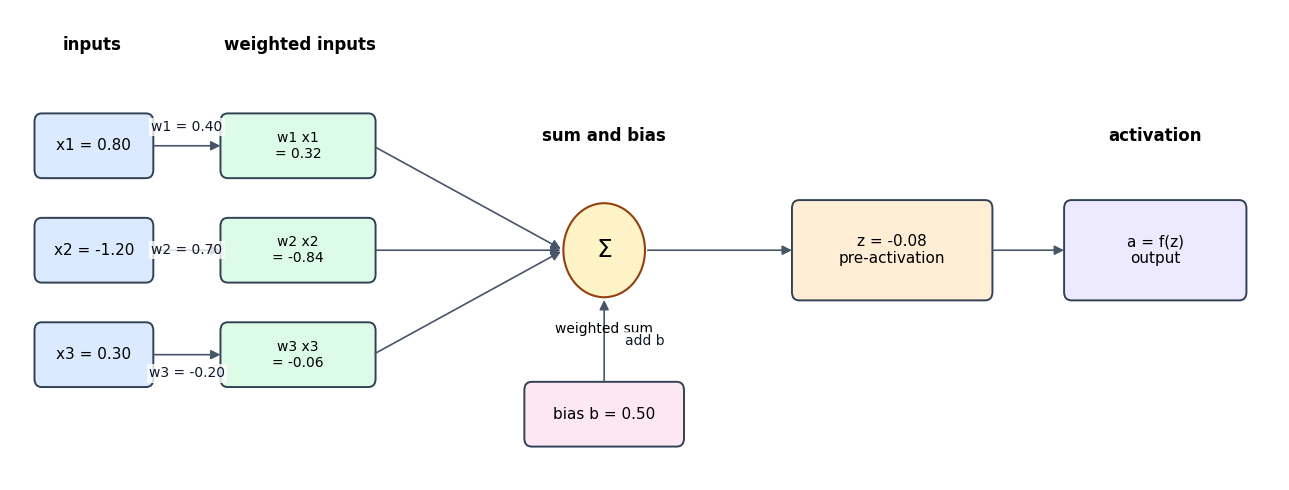

In [ ]:
weighted_inputs = x * w

fig, ax = plt.subplots(figsize=(13, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4.5)
ax.axis("off")


def add_box(x0, y0, width, height, text, facecolor, fontsize=11):
    box = FancyBboxPatch(
        (x0, y0),
        width,
        height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4,
        edgecolor="#334155",
        facecolor=facecolor,
    )
    ax.add_patch(box)
    ax.text(
        x0 + width / 2,
        y0 + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
    )


def add_arrow(x0, y0, x1, y1, label=None, label_offset=(0, 0)):
    arrow = FancyArrowPatch(
        (x0, y0),
        (x1, y1),
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.2,
        color="#475569",
    )
    ax.add_patch(arrow)
    if label is not None:
        ax.text(
            (x0 + x1) / 2 + label_offset[0],
            (y0 + y1) / 2 + label_offset[1],
            label,
            ha="center",
            va="center",
            fontsize=10,
            color="#0f172a",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
        )


input_y = [3.2, 2.2, 1.2]
for index, y_value in enumerate(input_y):
    add_box(
        0.3,
        y_value - 0.28,
        1.25,
        0.56,
        f"x{index + 1} = {x[index]:.2f}",
        "#dbeafe",
    )
    add_box(
        2.35,
        y_value - 0.28,
        1.65,
        0.56,
        f"w{index + 1} x{index + 1}\n= {weighted_inputs[index]:.2f}",
        "#dcfce7",
        fontsize=10,
    )
    add_arrow(
        1.55,
        y_value,
        2.35,
        y_value,
        label=f"w{index + 1} = {w[index]:.2f}",
        label_offset=(0, 0.18 if index == 0 else -0.18 if index == 2 else 0),
    )
    add_arrow(4.0, y_value, 6.1, 2.2)

sum_node = Circle(
    (6.55, 2.2), 0.45, facecolor="#fef3c7", edgecolor="#92400e", linewidth=1.5
)
ax.add_patch(sum_node)
ax.text(6.55, 2.2, "Σ", ha="center", va="center", fontsize=18)
ax.text(6.55, 1.45, "weighted sum", ha="center", va="center", fontsize=10)

add_box(5.7, 0.35, 1.7, 0.56, f"bias b = {b:.2f}", "#fce7f3")
add_arrow(6.55, 0.91, 6.55, 1.75, label="add b", label_offset=(0.45, 0))

add_arrow(7.0, 2.2, 8.65, 2.2)
add_box(8.65, 1.75, 2.15, 0.9, f"z = {z:.2f}\npre-activation", "#ffedd5")
add_arrow(10.8, 2.2, 11.65, 2.2)
add_box(11.65, 1.75, 1.95, 0.9, "a = f(z)\noutput", "#ede9fe")

ax.text(0.9, 4.12, "inputs", ha="center", fontsize=12, fontweight="bold")
ax.text(3.2, 4.12, "weighted inputs", ha="center", fontsize=12, fontweight="bold")
ax.text(6.55, 3.25, "sum and bias", ha="center", fontsize=12, fontweight="bold")
ax.text(12.62, 3.25, "activation", ha="center", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

### Questions

- What is the role of each weight?
- What would happen if one weight became very large?
- Why do we need the bias term?


## 2. Bias experiment


In [ ]:
bias_values = [-2.0, 0.0, 2.0]

for b in bias_values:
    z = x @ w + b
    print(f"b = {b:>4}: z = {z:.3f}")

b = -2.0: z = -2.580
b =  0.0: z = -0.580
b =  2.0: z = 1.420


### Interpretation

The bias shifts the neuron response independently of the input values.

For a linear decision boundary:

$$
\mathbf{w}^T\mathbf{x} + b = 0
$$

changing $b$ moves the boundary without changing its orientation.


# Part II — Activation functions


## 3. Implement common activations manually


In [ ]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def tanh(x):
    return np.tanh(x)


def relu(x):
    return np.maximum(0, x)


def leaky_relu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * x)

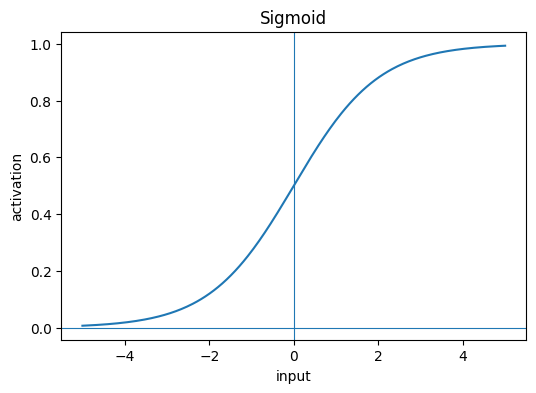

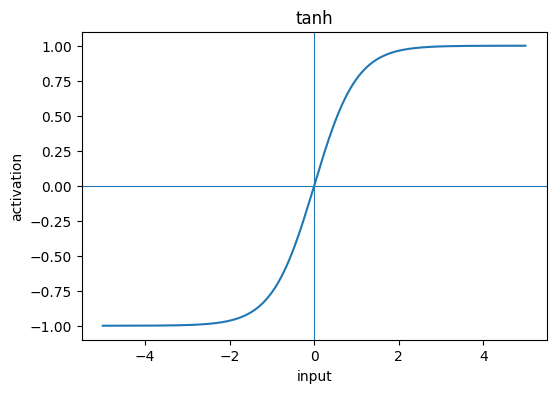

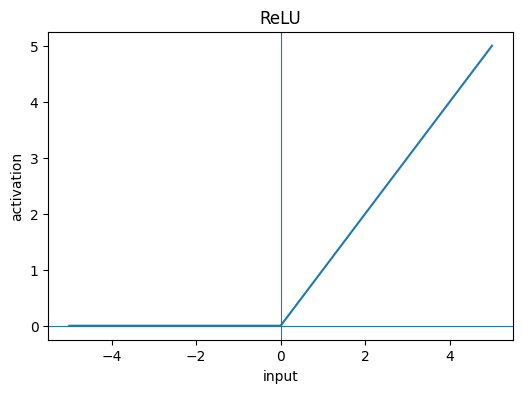

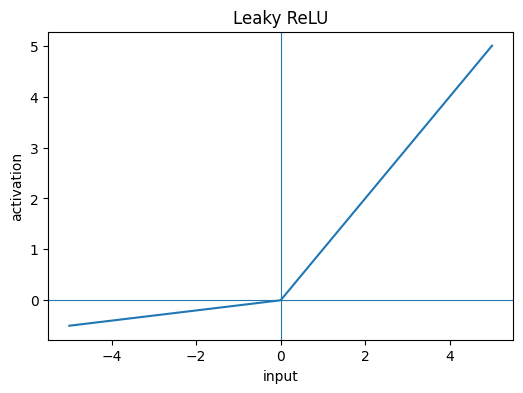

In [ ]:
x_grid = np.linspace(-5, 5, 300)

activations = {
    "Sigmoid": sigmoid(x_grid),
    "tanh": tanh(x_grid),
    "ReLU": relu(x_grid),
    "Leaky ReLU": leaky_relu(x_grid),
}

for name, values in activations.items():
    plt.figure(figsize=(6, 4))
    plt.plot(x_grid, values)
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.title(name)
    plt.xlabel("input")
    plt.ylabel("activation")
    plt.show()

# Part III — From one neuron to one dense layer


## 5. Matrix form

A layer with several neurons can be written as:

$$
\mathbf{z} = W\mathbf{x} + \mathbf{b}
$$

Each row of $W$ corresponds to one neuron.


In [ ]:
x = np.array([0.8, -1.2, 0.3])

W = np.array([[0.2, 0.4, -0.7], [0.8, -0.1, 0.3], [-0.5, 0.9, 0.2], [0.1, 0.4, 0.6]])

b = np.array([0.1, -0.2, 0.0, 0.3])

z = W @ x + b
tanh_out = tanh(z)

## 6. Dataset description

The student-facing file is week6/large_objects_m0_m1_m2_processed.csv. It was prepared from the microscopy object table before distribution.

Preparation choices:

- Keep rows with image_kind equal to large_object.
- Keep the classic segmentation variant so the same biological object is not represented four times by different segmentation methods.
- Convert the original group labels M0, M1, and M2 to the target values m0, m1, and m2.
- Replace the original experiment identifier with an anonymised sample_group identifier. This is metadata used for leakage-safe splitting, not a predictive feature.
- Retain numerical measurements describing object morphology, geometry, intensity, texture, and chromatin-related properties.
- Remove paths, object names, segmentation-method fields, image metadata, labels, and other identifiers that are not needed for modelling.

The resulting table contains 381 objects, 49 numerical features, 85 sample groups, and the following class counts:

| cell_type | objects |
| --------- | ------: |
| m0        |     132 |
| m1        |     104 |
| m2        |     145 |

Because several objects can originate from the same sample or experiment, observations from one sample_group must not be split between train, validation, and test sets.


In [8]:
from pathlib import Path

DATA_PATH = Path("week6/large_objects_m0_m1_m2_processed.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("large_objects_m0_m1_m2_processed.csv")

df = pd.read_csv(DATA_PATH)

print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.value_counts())

Data path: large_objects_m0_m1_m2_processed.csv
Shape: (381, 51)


,cell_type,sample_group,volume_voxels,volume_units3,surface_area_units2,sphericity,equivalent_diameter_units,centroid_z,centroid_y,centroid_x,...,surface_to_volume_ratio,equivalent_sphere_radius_units,inertia_eigval_0,inertia_eigval_1,inertia_eigval_2,inertia_anisotropy,centroid_z_norm_stack,centroid_y_norm_stack,centroid_x_norm_stack,distance_to_stack_center_units
0,m0,experiment_001,276743,276743.0,27809.851562,0.738476,80.852355,22.525292,75.822294,84.355601,...,0.100490,40.426177,1478.293368,904.118152,710.562956,0.519336,0.441672,0.486040,0.544230,7.940009
1,m0,experiment_001,283593,283593.0,29347.027344,0.711296,81.514017,25.895449,72.709143,78.685549,...,0.103483,40.757008,1532.955541,1024.523643,651.346833,0.575104,0.488593,0.466084,0.504395,4.936473
2,m0,experiment_001,251874,251874.0,29778.589844,0.647693,78.354072,24.460726,74.602913,77.450868,...,0.118228,39.177036,1627.794318,1089.952015,643.241744,0.604838,0.470399,0.521699,0.499683,3.776818
3,m0,experiment_001,245243,245243.0,29148.757812,0.650023,77.660348,24.147352,91.744735,80.677369,...,0.118857,38.830174,1662.394337,1062.755666,692.584305,0.583381,0.473477,0.588107,0.517163,14.619684
4,m0,experiment_001,282939,282939.0,29995.000000,0.694860,81.451308,23.316542,73.392434,78.215523,...,0.106012,40.725654,1582.797830,969.810146,738.997793,0.533107,0.457187,0.470464,0.501382,4.496454


float64    37
int64      12
object      2
Name: count, dtype: int64

## Universal biological data-preparation checklist

Use this checklist before starting the neural-network analysis. Tick an item only after inspecting the data or documenting a justified decision.

### Scientific purpose and provenance

- [x] Is the biological question and prediction task stated clearly?
- [x] Is the unit of observation clear: here, one row should represent one large microscopy object?
- [x] Do I know where the data came from and how the measurements were generated?
- [x] Have I recorded the data version, preprocessing history, and transformations already applied?

### Table shape and identifiers

- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [x] If the original assay had features in rows and samples in columns, was it transposed into the format expected by the analysis tool?
- [ ] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?
- [ ] Can every feature and observation be traced back to its source?
- [ ] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?


In [ ]:
display(pd.Series(df.columns, name="column"))


display(df.dtypes.rename("dtype").to_frame())


display(
    df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame()
)


for column in ["cell_type", "sample_group"]:
    print(f"{column}: {df[column].nunique()} unique values")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())

0                            cell_type
1                         sample_group
2                        volume_voxels
3                        volume_units3
4                  surface_area_units2
5                           sphericity
6            equivalent_diameter_units
7                           centroid_z
8                           centroid_y
9                           centroid_x
10                             bbox_z0
11                             bbox_y0
12                             bbox_x0
13                             bbox_z1
14                             bbox_y1
15                             bbox_x1
16                        bbox_depth_z
17                       bbox_height_y
18                        bbox_width_x
19                  bbox_volume_voxels
20                  bbox_fill_fraction
21                      mean_intensity
22                    median_intensity
23                       min_intensity
24                       max_intensity
25                       

,dtype
cell_type,object
sample_group,object
volume_voxels,int64
volume_units3,float64
surface_area_units2,float64
sphericity,float64
equivalent_diameter_units,float64
centroid_z,float64
centroid_y,float64
centroid_x,float64


,missing
surface_area_units2,13
sphericity,13
surface_to_volume_ratio,13
projected_circularity,13
cell_type,0
projected_perimeter_px,0
intensity_p90,0
integrated_intensity,0
intensity_cv,0
chromatin_condensation_parameter,0


cell_type: 3 unique values


,count
cell_type,
m2,145
m0,132
m1,104


sample_group: 85 unique values


,count
sample_group,
experiment_004,22
experiment_071,22
experiment_080,14
experiment_001,13
experiment_081,13
...,...
experiment_025,1
experiment_059,1
experiment_060,1


### Types, values, and measurement meaning

- [x] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [x] Are units, scales, encodings, reference categories, and detection limits understood?
- [x] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?
- [x] Are normalization, scaling, log transformation, and batch-correction steps documented?

### Missing values

- [x] Have I detected missing values using the dataset's actual missing-value representations, not only NaN?
- [x] Have I measured missingness by row, column, group, and relevant batch or time variable?
- [x] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?
- [x] Have I justified whether to retain, remove, or impute missing values?
- [ ] If imputing, will the imputer be fitted on training data only and then applied to validation and test data?


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 51 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   cell_type                         381 non-null    object 
 1   sample_group                      381 non-null    object 
 2   volume_voxels                     381 non-null    int64  
 3   volume_units3                     381 non-null    float64
 4   surface_area_units2               368 non-null    float64
 5   sphericity                        368 non-null    float64
 6   equivalent_diameter_units         381 non-null    float64
 7   centroid_z                        381 non-null    float64
 8   centroid_y                        381 non-null    float64
 9   centroid_x                        381 non-null    float64
 10  bbox_z0                           381 non-null    int64  
 11  bbox_y0                           381 non-null    int64  
 12  bbox_x0 

In [ ]:
display(df.describe().T)


display(
    df.isna().sum().sort_values(ascending=False).head(15).rename("missing").to_frame()
)

,count,mean,std,min,25%,50%,75%,max
volume_voxels,381.0,8.112129e+05,4.128121e+06,1.772930e+05,3.000220e+05,3.762040e+05,5.310970e+05,6.180274e+07
volume_units3,381.0,8.112129e+05,4.128121e+06,1.772930e+05,3.000220e+05,3.762040e+05,5.310970e+05,6.180274e+07
surface_area_units2,368.0,4.781240e+04,2.956593e+04,1.940683e+04,3.071611e+04,3.833912e+04,5.163522e+04,1.922112e+05
sphericity,368.0,6.468251e-01,1.049543e-01,3.452301e-01,5.690141e-01,6.565045e-01,7.210297e-01,8.586280e-01
equivalent_diameter_units,381.0,9.682969e+01,3.396765e+01,6.969971e+01,8.305864e+01,8.956567e+01,1.004751e+02,4.905347e+02
centroid_z,381.0,2.792631e+01,5.114021e+00,1.600000e+01,2.471158e+01,2.758301e+01,3.031702e+01,4.844828e+01
centroid_y,381.0,1.063140e+02,4.846952e+01,3.900000e+01,7.939970e+01,9.248645e+01,1.171447e+02,5.275000e+02
centroid_x,381.0,1.042225e+02,4.271740e+01,3.000000e+01,7.914662e+01,9.122094e+01,1.140194e+02,4.215000e+02
bbox_z0,381.0,7.669291e+00,4.182775e+00,0.000000e+00,6.000000e+00,7.000000e+00,9.000000e+00,3.200000e+01
bbox_y0,381.0,2.770604e+01,2.135163e+01,0.000000e+00,1.500000e+01,2.200000e+01,3.400000e+01,1.960000e+02


,missing
surface_area_units2,13
sphericity,13
surface_to_volume_ratio,13
projected_circularity,13
cell_type,0
projected_perimeter_px,0
intensity_p90,0
integrated_intensity,0
intensity_cv,0
chromatin_condensation_parameter,0


In [ ]:
constant_features = [
    column for column in df.columns if df[column].nunique(dropna=False) <= 1
]
constant_features

[]

In [ ]:
display(df["cell_type"].value_counts().sort_index().rename("objects").to_frame())
display(df["sample_group"].value_counts().to_frame("objects_per_group"))

,objects
cell_type,
m0,132
m1,104
m2,145


,objects_per_group
sample_group,
experiment_004,22
experiment_071,22
experiment_080,14
experiment_001,13
experiment_081,13
...,...
experiment_025,1
experiment_059,1
experiment_060,1


In [14]:
candidate_features = df.select_dtypes(include=np.number).columns.tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 49
['volume_voxels', 'volume_units3', 'surface_area_units2', 'sphericity', 'equivalent_diameter_units', 'centroid_z', 'centroid_y', 'centroid_x', 'bbox_z0', 'bbox_y0']


### Replicates, dependence, and grouping

- [x] Have I checked for exact duplicates and near-duplicate observations?
- [x] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [x] Is the independent biological unit identified by a grouping variable?
- [x] Will all related observations and their derivatives remain in the same train, validation, and test split?
- [ ] If augmented or synthetic observations were created, is their provenance recorded and reproducible?

### Target, leakage, and study design

- [x] Is the target defined before modelling, with its classes checked for balance and validity?
- [ ] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?
- [ ] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?
- [ ] Have I checked whether the target is associated with a technical or grouping variable?
- [ ] Does the planned split represent the biological generalization question?


In [15]:
candidate_features = df.select_dtypes(include=np.number).columns.tolist()

print("Candidate numerical features:", len(candidate_features))
print(candidate_features[:10])

Candidate numerical features: 49
['volume_voxels', 'volume_units3', 'surface_area_units2', 'sphericity', 'equivalent_diameter_units', 'centroid_z', 'centroid_y', 'centroid_x', 'bbox_z0', 'bbox_y0']


### Reproducibility and decision record

- [x] Are random seeds, software versions, file names, and input/output shapes recorded?
- [x] Are all preprocessing steps placed in a reproducible pipeline?
- [x] Have I recorded unresolved data-quality concerns and the decisions made about them?
- [x] Can another person explain what each row, column, feature, target, and grouping variable means?


## 8. Small exploratory data analysis

Before splitting or fitting a model, inspect the target balance, group sizes, and several representative feature distributions. These plots are for exploration, not feature selection.


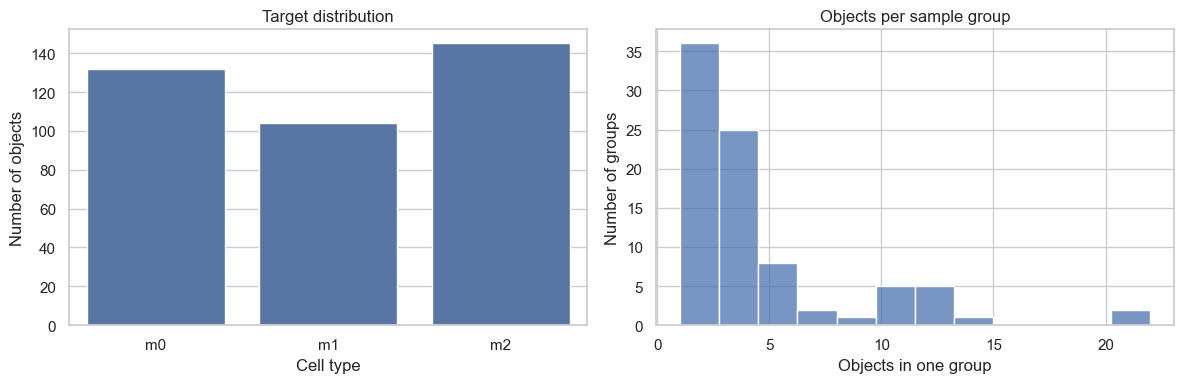

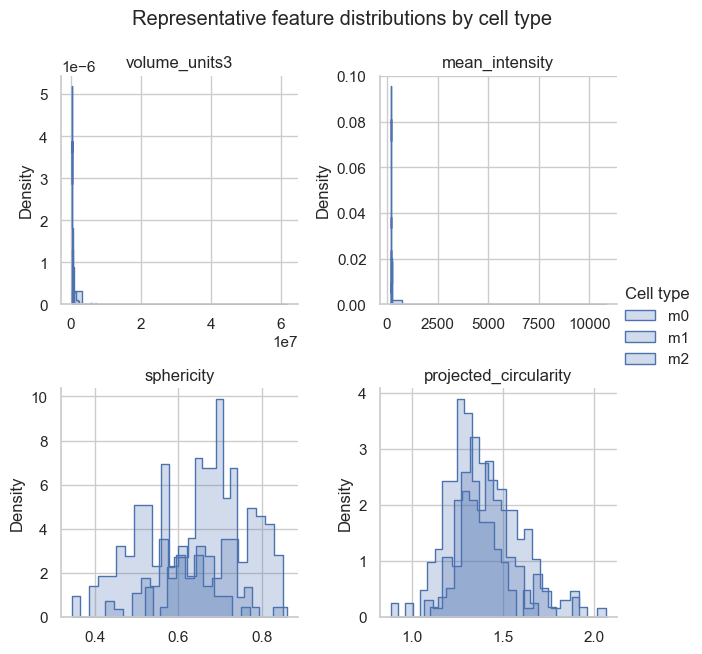

In [ ]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plot_features = [
    column
    for column in [
        "volume_units3",
        "mean_intensity",
        "sphericity",
        "projected_circularity",
    ]
    if column in df.columns
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="cell_type",
    order=["m0", "m1", "m2"],
    ax=axes[0],
)
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Cell type")
axes[0].set_ylabel("Number of objects")

group_sizes = df["sample_group"].value_counts()
sns.histplot(group_sizes, bins=12, ax=axes[1])
axes[1].set_title("Objects per sample group")
axes[1].set_xlabel("Objects in one group")
axes[1].set_ylabel("Number of groups")

plt.tight_layout()
plt.show()

if plot_features:
    long_features = df.melt(
        id_vars=["cell_type"],
        value_vars=plot_features,
        var_name="feature",
        value_name="value",
    )
    g = sns.FacetGrid(
        long_features,
        col="feature",
        col_wrap=2,
        hue="cell_type",
        sharex=False,
        sharey=False,
        height=3.2,
    )
    g.map_dataframe(
        sns.histplot,
        bins=20,
        element="step",
        stat="density",
        common_norm=False,
    )
    g.add_legend(title="Cell type")
    g.set_titles("{col_name}")
    g.fig.suptitle("Representative feature distributions by cell type", y=1.02)
    plt.show()

## 9. Association between the target and numerical features

The target is categorical, while the predictors are numerical. Two descriptive measures are useful:

- Mutual information estimates how much information a feature contains about the cell-type label.
- Eta squared measures the fraction of feature variance explained by differences between target groups.

For a feature X and target Y:

$$
I(X;Y)
=
\sum_{x,y}
p(x,y)
\log
\left(
\frac{p(x,y)}{p(x)p(y)}
\right)
$$

The formula compares the observed joint distribution with the distribution expected if X and Y were independent.

- If X and Y are independent, mutual information is 0.
- Larger values indicate stronger statistical dependence.
- Mutual information is not directional and does not prove biological causation.

These statistics are exploratory. They are not used as a substitute for group-aware evaluation.


,feature,eta_squared,mutual_information
0,bbox_y1,0.198766,0.393736
1,centroid_y,0.234275,0.383773
2,inertia_eigval_1,0.025528,0.377478
3,centroid_x,0.322398,0.357841
4,bbox_x1,0.306146,0.357505
5,inertia_eigval_0,0.022391,0.345199
6,chromatin_inner_area_px,0.023219,0.319404
7,surface_area_units2,0.402473,0.315076
8,projected_perimeter_px,0.356575,0.313204
9,projected_area_units2,0.026228,0.303000


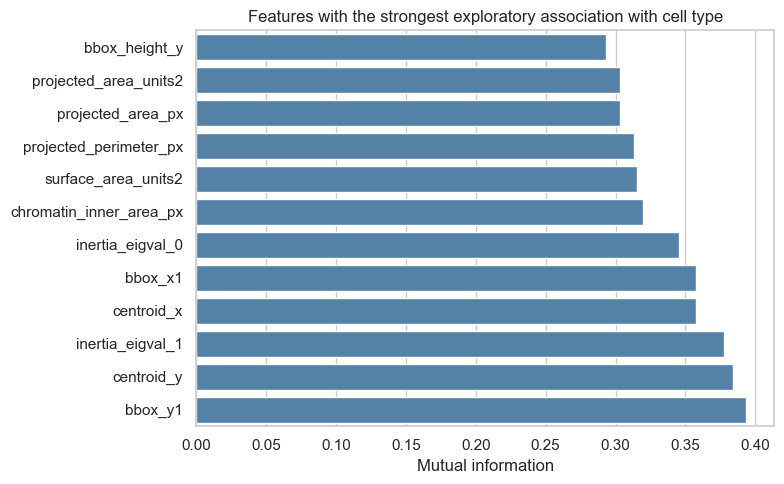

In [ ]:
from sklearn.feature_selection import mutual_info_classif

association_rows = []
target_codes = df["cell_type"].map({"m0": 0, "m1": 1, "m2": 2})

for feature in candidate_features:
    values = df[feature]
    valid = values.notna() & target_codes.notna()
    feature_values = values[valid].to_numpy()
    feature_target = target_codes[valid].to_numpy()

    if len(feature_values) < 3 or np.isclose(np.var(feature_values), 0):
        eta_squared = np.nan
        mutual_information = 0.0
    else:
        grand_mean = feature_values.mean()
        grouped = pd.DataFrame(
            {
                "value": feature_values,
                "target": feature_target,
            }
        ).groupby("target")["value"]
        group_means = grouped.mean()
        group_counts = grouped.size()
        ss_between = ((group_means - grand_mean) ** 2 * group_counts).sum()
        ss_total = ((feature_values - grand_mean) ** 2).sum()
        eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

        mutual_information = mutual_info_classif(
            pd.DataFrame({feature: feature_values}),
            feature_target,
            random_state=RANDOM_STATE,
        )[0]

    association_rows.append(
        {
            "feature": feature,
            "eta_squared": eta_squared,
            "mutual_information": mutual_information,
        }
    )

association = (
    pd.DataFrame(association_rows)
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

display(association.head(15))

top_association = association.head(12).sort_values("mutual_information")
plt.figure(figsize=(8, 5))
sns.barplot(
    data=top_association,
    x="mutual_information",
    y="feature",
    color="steelblue",
)
plt.title("Features with the strongest exploratory association with cell type")
plt.xlabel("Mutual information")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 10. Define feature columns and metadata

The processed table has only two non-feature columns:

- cell_type: the classification target.
- sample_group: an anonymised sample/experiment grouping variable.

All remaining columns are numerical measurements and can be used as model inputs. The group column is kept separately so related observations can remain in the same data split.


In [18]:
TARGET = "cell_type"
GROUP_COLUMN = "sample_group"
META_COLUMNS = [TARGET, GROUP_COLUMN]

feature_cols = [column for column in df.columns if column not in META_COLUMNS]
X = df[feature_cols].copy()
y = df[TARGET].copy()
groups = df[GROUP_COLUMN].copy()

print("Number of features:", len(feature_cols))
print("Feature matrix shape:", X.shape)
print("Target values:", sorted(y.unique()))
print("Number of sample groups:", groups.nunique())

Number of features: 49
Feature matrix shape: (381, 49)
Target values: ['m0', 'm1', 'm2']
Number of sample groups: 85


## 12. Create a reproducible stratified group-aware test split

Cells from the same biological sample or experiment are not independent. At the same time, a random choice of groups can produce an unusually unbalanced test set.

We use `StratifiedGroupKFold` to satisfy both requirements:

- every group stays entirely in one partition;
- the class proportions are kept approximately similar across folds;
- shuffling and the fixed random seed make the split reproducible.

We select one of five outer folds as the test set. The selection is based only on split quality: test-size closeness to 20% and similarity to the overall class proportions.


In [19]:
def split_quality(test_indices, y_values, target_fraction):
    overall_proportions = y_values.value_counts(normalize=True).sort_index()
    test_proportions = (
        y_values.iloc[test_indices]
        .value_counts(normalize=True)
        .reindex(overall_proportions.index)
        .fillna(0)
    )
    size_error = abs(len(test_indices) / len(y_values) - target_fraction)
    class_error = np.abs(test_proportions - overall_proportions).sum()
    return size_error + class_error


outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)
outer_splits = list(outer_splitter.split(X, y, groups=groups))

outer_fold_index = min(
    range(len(outer_splits)),
    key=lambda index: split_quality(
        outer_splits[index][1],
        y,
        target_fraction=0.20,
    ),
)
train_idx, test_idx = outer_splits[outer_fold_index]

X_train_full = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train_full = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_train_full = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

shared_groups = set(groups_train_full).intersection(groups_test)

print("Selected outer fold:", outer_fold_index)
print("Training objects:", len(X_train_full))
print("Test objects:", len(X_test))
print("Training groups:", groups_train_full.nunique())
print("Test groups:", groups_test.nunique())
print("Shared groups:", len(shared_groups))
print("Overall class proportions:")
print(y.value_counts(normalize=True).sort_index())
print("Test class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

assert len(shared_groups) == 0
assert set(y_test.unique()) == set(y.unique())

Selected outer fold: 3
Training objects: 281
Test objects: 100
Training groups: 68
Test groups: 17
Shared groups: 0
Overall class proportions:
cell_type
m0    0.346457
m1    0.272966
m2    0.380577
Name: proportion, dtype: float64
Test class proportions:
cell_type
m0    0.40
m1    0.22
m2    0.38
Name: proportion, dtype: float64


## 13. Create a stratified group-aware validation split

The validation set is created only from the training portion. It is also stratified by class and separated by group, so it can be used for early stopping and model selection without touching the final test set.


In [20]:
inner_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)
inner_splits = list(
    inner_splitter.split(
        X_train_full,
        y_train_full,
        groups=groups_train_full,
    )
)

inner_fold_index = min(
    range(len(inner_splits)),
    key=lambda index: split_quality(
        inner_splits[index][1],
        y_train_full,
        target_fraction=0.25,
    ),
)
train_idx2, val_idx = inner_splits[inner_fold_index]

X_train = X_train_full.iloc[train_idx2].copy()
X_val = X_train_full.iloc[val_idx].copy()
y_train = y_train_full.iloc[train_idx2].copy()
y_val = y_train_full.iloc[val_idx].copy()
groups_train = groups_train_full.iloc[train_idx2].copy()
groups_val = groups_train_full.iloc[val_idx].copy()

shared_train_val_groups = set(groups_train).intersection(groups_val)

print("Selected inner fold:", inner_fold_index)
print("Training objects:", len(X_train))
print("Validation objects:", len(X_val))
print("Training groups:", groups_train.nunique())
print("Validation groups:", groups_val.nunique())
print("Shared train/validation groups:", len(shared_train_val_groups))
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("Validation class proportions:")
print(y_val.value_counts(normalize=True).sort_index())

assert len(shared_train_val_groups) == 0
assert set(y_val.unique()) == set(y.unique())

Selected inner fold: 0
Training objects: 211
Validation objects: 70
Training groups: 52
Validation groups: 16
Shared train/validation groups: 0
Training class proportions:
cell_type
m0    0.350711
m1    0.289100
m2    0.360190
Name: proportion, dtype: float64
Validation class proportions:
cell_type
m0    0.257143
m1    0.300000
m2    0.442857
Name: proportion, dtype: float64


# Part VI — Scaling


## 14. Impute and standardize features

The inspection showed missing values in some derived geometry features. We will retain those rows and impute missing feature values with the training-set median.

Both the imputer and the scaler are fitted on training data only. The validation and test sets are transformed using those fitted objects, preventing information from those sets from influencing preprocessing.


In [21]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing values before imputation:")
print("train:", int(X_train.isna().sum().sum()))
print("validation:", int(X_val.isna().sum().sum()))
print("test:", int(X_test.isna().sum().sum()))

print("Scaled shapes:")
print("train:", X_train_scaled.shape)
print("validation:", X_val_scaled.shape)
print("test:", X_test_scaled.shape)
print("Missing values after imputation:", int(np.isnan(X_train_scaled).sum()))
print("First five training means:", X_train_scaled.mean(axis=0)[:5])
print("First five training standard deviations:", X_train_scaled.std(axis=0)[:5])

Missing values before imputation:
train: 8
validation: 8
test: 36
Scaled shapes:
train: (211, 49)
validation: (70, 49)
test: (100, 49)
Missing values after imputation: 0
First five training means: [-6.62976782e-17 -6.62976782e-17 -5.05125168e-17 -1.18704414e-15
  0.00000000e+00]
First five training standard deviations: [1. 1. 1. 1. 1.]


## Exploratory t-SNE visualization

The following plot provides a two-dimensional visual summary of the processed feature space. Points are coloured by cell type.

t-SNE is used here only for exploration. It is not a predictive model, and the embedding should not be used to evaluate the classifier or replace group-aware splitting.


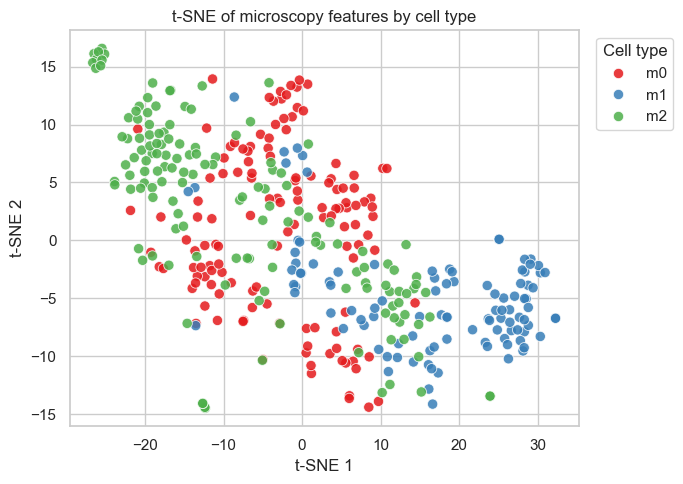

In [ ]:
X_all_scaled = scaler.transform(imputer.transform(X))

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_all_scaled)

tsne_plot = pd.DataFrame(
    {
        "TSNE1": X_tsne[:, 0],
        "TSNE2": X_tsne[:, 1],
        "cell_type": y.to_numpy(),
    }
)

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=tsne_plot,
    x="TSNE1",
    y="TSNE2",
    hue="cell_type",
    hue_order=["m0", "m1", "m2"],
    palette="Set1",
    s=55,
    alpha=0.85,
)
plt.title("t-SNE of microscopy features by cell type")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Part VII — Convert data to PyTorch tensors


In [23]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

class_names = sorted(y.unique())
class_to_index = {name: index for index, name in enumerate(class_names)}

y_train_t = torch.tensor(
    y_train.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_val_t = torch.tensor(
    y_val.map(class_to_index).to_numpy(),
    dtype=torch.long,
)
y_test_t = torch.tensor(
    y_test.map(class_to_index).to_numpy(),
    dtype=torch.long,
)

print("Class mapping:", class_to_index)
print("Training tensor shapes:", X_train_t.shape, y_train_t.shape)
print("Validation tensor shapes:", X_val_t.shape, y_val_t.shape)
print("Test tensor shapes:", X_test_t.shape, y_test_t.shape)

Class mapping: {'m0': 0, 'm1': 1, 'm2': 2}
Training tensor shapes: torch.Size([211, 49]) torch.Size([211])
Validation tensor shapes: torch.Size([70, 49]) torch.Size([70])
Test tensor shapes: torch.Size([100, 49]) torch.Size([100])


In [24]:
y_test_t

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2])

## 16. Create Dataset and DataLoader objects


In [25]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 7
Validation batches: 3
Test batches: 4


# Part VIII — First MLP


## 17. Define a simple network

Suggested starting architecture:

$$
p \rightarrow 32 \rightarrow 16 \rightarrow K
$$

where:

- $p$ = number of input features
- $K$ = number of classes


In [ ]:
class MLP(nn.Module):
    def __init__(self, input_dim, n_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, n_classes),
        )

    def forward(self, x):
        return self.network(x)

In [27]:
input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)

model = MLP(
    input_dim=input_dim,
    n_classes=n_classes,
).to(DEVICE)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=49, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


## 18. Visualise the mMLP with torchview

The graph is generated from the actual PyTorch model, so it reflects the layers used in training. Tensor shapes make the transition from a batch of 49 microscopy features to three class logits explicit.


In [ ]:
import shutil
from torchview import draw_graph

sample_input = torch.zeros((1, input_dim), dtype=torch.float32, device=DEVICE)
model_graph = draw_graph(
    model,
    input_data=sample_input,
    expand_nested=True,
    graph_name="microscopy_mlp",
)

if shutil.which("dot") is not None:
    # The Python graphviz package uses the Graphviz `dot` executable to
    # render this structural graph as an image in Jupyter.
    display(model_graph.visual_graph)
else:
    # torchview still created the graph; show its DOT source without raising
    # an error when only the Python package is installed.
    print(
        "Graphviz executable not found. Install Graphviz and reopen the notebook to render the image."
    )
    print("The torchview DOT source was generated successfully:")
    print(model_graph.visual_graph.source)

ModuleNotFoundError: No module named 'torchview'

## 19. Count trainable parameters


In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print("Trainable parameters:", count_parameters(model))

Trainable parameters: 2179


### Manual check

For:

```text
input_dim → 32 → 16 → K
```

calculate the parameter count manually before comparing with PyTorch.


# Part IX — Logits and loss


## 20. What does the model output?

For multiclass classification, the last layer outputs **logits**.

Do not add `Softmax()` inside the model when using:

```python
nn.CrossEntropyLoss()
```

because `CrossEntropyLoss` already handles the required transformation internally.


In [ ]:
criterion = nn.CrossEntropyLoss()

with torch.no_grad():
    logits = model(X_train_t[:5].to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)

print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Probabilities:")
display(probabilities.cpu().numpy())
print("Probability sums:", probabilities.sum(dim=1).cpu().numpy())

Logits shape: torch.Size([5, 3])
Probabilities shape: torch.Size([5, 3])
Probabilities:


array([[0.36189035, 0.34712702, 0.29098263],
       [0.3712637 , 0.3454677 , 0.2832686 ],
       [0.37033245, 0.3369179 , 0.29274958],
       [0.35457015, 0.34976077, 0.29566902],
       [0.37909147, 0.34151652, 0.27939206]], dtype=float32)

Probability sums: [1.         1.         0.9999999  0.99999994 1.        ]


# Part X — Training loop


## 21. The five central lines

```python
optimizer.zero_grad()
pred = model(X_batch)
loss = criterion(pred, y_batch)
loss.backward()
optimizer.step()
```

These implement:

$$
forward \rightarrow loss \rightarrow gradients \rightarrow update
$$


In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 22. Training function


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (total_loss / total_samples, total_correct / total_samples)

## 23. Validation function


In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)

        pred = logits.argmax(dim=1)

        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return (total_loss / total_samples, total_correct / total_samples)

## 24. Full training loop


In [ ]:
N_EPOCHS = 100

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE
    )

    val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:03d} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_loss:.4f} | "
            f"train acc={train_acc:.3f} | "
            f"val acc={val_acc:.3f}"
        )

Epoch 005 | train loss=0.9045 | val loss=1.3871 | train acc=0.661 | val acc=0.731
Epoch 010 | train loss=0.7368 | val loss=2.5432 | train acc=0.639 | val acc=0.705
Epoch 015 | train loss=0.6522 | val loss=2.9976 | train acc=0.692 | val acc=0.718
Epoch 020 | train loss=0.5777 | val loss=3.2725 | train acc=0.749 | val acc=0.731
Epoch 025 | train loss=0.5001 | val loss=3.4398 | train acc=0.797 | val acc=0.769
Epoch 030 | train loss=0.4288 | val loss=4.2840 | train acc=0.819 | val acc=0.782
Epoch 035 | train loss=0.3597 | val loss=5.0755 | train acc=0.890 | val acc=0.744
Epoch 040 | train loss=0.3093 | val loss=6.1148 | train acc=0.903 | val acc=0.795
Epoch 045 | train loss=0.2691 | val loss=5.6637 | train acc=0.930 | val acc=0.782
Epoch 050 | train loss=0.2330 | val loss=7.2934 | train acc=0.930 | val acc=0.795
Epoch 055 | train loss=0.2103 | val loss=7.6174 | train acc=0.943 | val acc=0.808
Epoch 060 | train loss=0.1832 | val loss=8.7769 | train acc=0.956 | val acc=0.782
Epoch 065 | trai

## 25. Plot learning curves


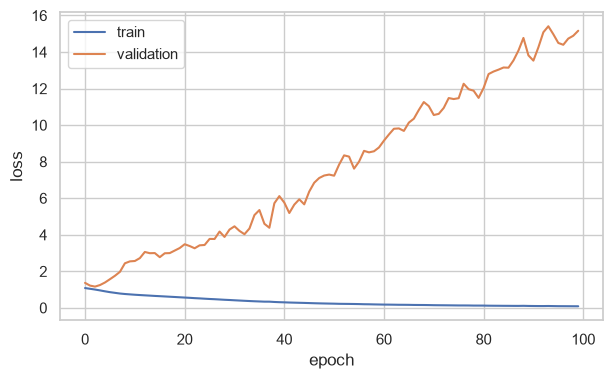

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## Tracking experiments with a local MLflow server

Notebook output is useful while we work, but it is difficult to compare after several training runs. MLflow stores parameters, metrics, figures, and model artifacts in a searchable experiment database.

For this practical, start the MLflow server in a **separate terminal from the project root** before running the code cell below:

```text
uv run mlflow server --host 127.0.0.1 --port 5000 --workers 1 --backend-store-uri sqlite:///week6/mlflow.db --allowed-hosts localhost,127.0.0.1,localhost:5000,127.0.0.1:5000
```

Then open `http://127.0.0.1:5000` in a browser. The notebook connects to this local server through its HTTP API; it does not create or manage the database itself. The database and artifact directory are local teaching files and should not be committed to GitHub.

In the following cell we log:

- model and training parameters;
- metrics at every epoch;
- a learning-curve figure;
- a CPU-compatible PyTorch `state_dict` artifact.


In [ ]:
import os
import tempfile
from pathlib import Path

import sys
import importlib

# Positron can expose its own typing_extensions before the project environment.
# MLflow/FastAPI needs the newer sentinel symbol, so prioritize this project's
# site-packages before importing MLflow.
project_roots = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (
        root
        for root in project_roots
        if (root / ".venv" / "Lib" / "site-packages").exists()
    ),
    None,
)
if project_root is None:
    raise RuntimeError(
        "Could not locate the practicals .venv. Select the project kernel or run the notebook from the project directory."
    )

project_site_packages = str(project_root / ".venv" / "Lib" / "site-packages")
if project_site_packages not in sys.path:
    sys.path.insert(0, project_site_packages)

loaded_typing_extensions = sys.modules.get("typing_extensions")
if loaded_typing_extensions is not None and not hasattr(
    loaded_typing_extensions, "sentinel"
):
    del sys.modules["typing_extensions"]
    importlib.invalidate_caches()

import typing_extensions

if not hasattr(typing_extensions, "sentinel"):
    raise RuntimeError(
        f"The active kernel is using an incompatible typing_extensions package: {typing_extensions.__file__}"
    )

import mlflow

tracking_uri = os.environ.get("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("week6-microscopy-mlp")


def make_training_figure(series):
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(series["train_loss"], label="train")
    axes[0].plot(series["validation_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(series["train_accuracy"], label="train")
    axes[1].plot(series["validation_accuracy"], label="validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    figure.tight_layout()
    return figure


def log_mlflow_training_run(
    run_name,
    params,
    series=None,
    final_metrics=None,
    model=None,
    model_type=None,
    figure=None,
):
    """Log one comparable experiment to the local MLflow server."""
    params = dict(params)
    if model_type is not None:
        params["model_type"] = model_type

    with mlflow.start_run(run_name=run_name) as active_run:
        mlflow.log_params(params)

        if series:
            for metric_name, values in series.items():
                for epoch, value in enumerate(values, start=1):
                    mlflow.log_metric(metric_name, float(value), step=epoch)

        if final_metrics:
            mlflow.log_metrics(
                {name: float(value) for name, value in final_metrics.items()}
            )

        if figure is not None:
            mlflow.log_figure(figure, "training_curves.png")

        if model is not None:
            with tempfile.TemporaryDirectory() as temporary_directory:
                temporary_directory = Path(temporary_directory)
                if model_type == "pytorch":
                    artifact_file = temporary_directory / "pytorch_state_dict.pt"
                    torch.save(
                        copy.deepcopy(model).to("cpu").state_dict(),
                        artifact_file,
                    )
                elif model_type == "keras":
                    artifact_file = temporary_directory / "keras_model.keras"
                    model.save(artifact_file)
                elif model_type == "xgboost":
                    artifact_file = temporary_directory / "xgboost_model.json"
                    model.save_model(str(artifact_file))
                else:
                    raise ValueError(f"Unsupported model_type: {model_type}")
                mlflow.log_artifact(str(artifact_file), artifact_path="model")

        return active_run.info.run_id


baseline_series = {
    "train_loss": history["train_loss"],
    "validation_loss": history["val_loss"],
    "train_accuracy": history["train_acc"],
    "validation_accuracy": history["val_acc"],
}
baseline_figure = make_training_figure(baseline_series)
baseline_run_id = log_mlflow_training_run(
    run_name="pytorch-baseline",
    params={
        "framework": "pytorch",
        "input_dim": input_dim,
        "hidden_layers": "32,16",
        "n_classes": n_classes,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "epochs": len(history["train_loss"]),
        "batch_size": BATCH_SIZE,
        "random_state": RANDOM_STATE,
    },
    series=baseline_series,
    final_metrics={
        "final_validation_loss": history["val_loss"][-1],
        "final_validation_accuracy": history["val_acc"][-1],
        "best_validation_accuracy": max(history["val_acc"]),
    },
    model=model,
    model_type="pytorch",
    figure=baseline_figure,
)
plt.show()
plt.close(baseline_figure)
print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow baseline run ID:", baseline_run_id)

KeyboardInterrupt: 

# Part XI — Inspect gradients


## 26. Gradient norms

After `loss.backward()`, every trainable parameter should usually have a gradient.

Inspect gradient magnitude.


In [ ]:
for name, param in model.named_parameters():
    if param.grad is not None:
        print(name, tuple(param.shape), param.grad.norm().item())

network.0.weight (32, 49) 1.6831750869750977
network.0.bias (32,) 0.5307906866073608
network.2.weight (16, 32) 0.9804710149765015
network.2.bias (16,) 0.2735550105571747
network.4.weight (3, 16) 0.8199415802955627
network.4.bias (3,) 0.17573408782482147


### Questions

- What would gradients close to zero imply?
- What would extremely large gradients suggest?
- How might activation choice affect this?


# Part XII — Learning-rate experiment


## 27. Train identical models with different learning rates

Suggested values:

```python
1e-5
1e-3
1e-1
```

Keep everything else identical.


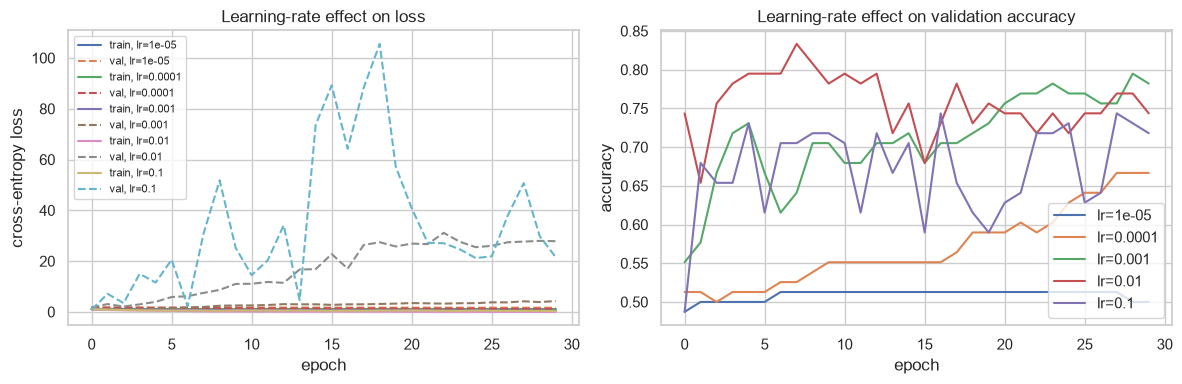

🏃 View run mlp-learning-rate-1e-05 at: http://127.0.0.1:5000/#/experiments/1/runs/09384fcbea1243b089aabb8469d799d7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.0001 at: http://127.0.0.1:5000/#/experiments/1/runs/5211a502cc524ab8b171b457561d33c6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.001 at: http://127.0.0.1:5000/#/experiments/1/runs/53b42e3039f0490781562c249bb2f9fb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.01 at: http://127.0.0.1:5000/#/experiments/1/runs/71f99668dc3247a3911eabe5d68e4bd4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-learning-rate-0.1 at: http://127.0.0.1:5000/#/experiments/1/runs/e978038a9cd64fadb0c8875ff69c9a44
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [ ]:
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim

        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    weight_decay=0.0,
    dropout=0.0,
    epochs=30,
    patience=None,
):
    torch.manual_seed(RANDOM_STATE)

    experiment_model = FlexibleMLP(
        input_dim=input_dim,
        n_classes=n_classes,
        hidden_dims=hidden_dims,
        dropout=dropout,
    ).to(DEVICE)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    experiment_history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    best_state = None
    best_val_loss = np.inf
    best_epoch = epochs
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            experiment_model,
            train_loader,
            criterion,
            experiment_optimizer,
            DEVICE,
        )
        val_loss, val_acc = evaluate(
            experiment_model,
            val_loader,
            criterion,
            DEVICE,
        )

        experiment_history["train_loss"].append(train_loss)
        experiment_history["val_loss"].append(val_loss)
        experiment_history["train_acc"].append(train_acc)
        experiment_history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(experiment_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if patience is not None and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        experiment_model.load_state_dict(best_state)

    return experiment_model, experiment_history, best_epoch


learning_rates = [1e-5, 1e-4, 1e-3, 1e-2, 0.1]
learning_rate_results = {}
learning_rate_models = {}

for learning_rate in learning_rates:
    learning_rate_model, history_lr, best_epoch_lr = fit_experiment(
        lr=learning_rate,
        epochs=30,
    )
    learning_rate_models[learning_rate] = learning_rate_model
    learning_rate_results[learning_rate] = {
        "history": history_lr,
        "best_epoch": best_epoch_lr,
    }

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    axes[0].plot(history_lr["train_loss"], label=f"train, lr={learning_rate:g}")
    axes[0].plot(
        history_lr["val_loss"], linestyle="--", label=f"val, lr={learning_rate:g}"
    )
    axes[1].plot(history_lr["val_acc"], label=f"lr={learning_rate:g}")

axes[0].set_title("Learning-rate effect on loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Learning-rate effect on validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

for learning_rate, result in learning_rate_results.items():
    history_lr = result["history"]
    lr_series = {
        "train_loss": history_lr["train_loss"],
        "validation_loss": history_lr["val_loss"],
        "train_accuracy": history_lr["train_acc"],
        "validation_accuracy": history_lr["val_acc"],
    }
    log_mlflow_training_run(
        run_name=f"mlp-learning-rate-{learning_rate:g}",
        params={
            "framework": "pytorch",
            "architecture": "32,16",
            "learning_rate": learning_rate,
            "requested_epochs": 30,
            "actual_epochs": len(history_lr["train_loss"]),
            "best_epoch": result["best_epoch"],
            "batch_size": BATCH_SIZE,
            "random_state": RANDOM_STATE,
        },
        series=lr_series,
        final_metrics={
            "best_validation_accuracy": max(history_lr["val_acc"]),
            "best_validation_loss": min(history_lr["val_loss"]),
        },
        model=learning_rate_models[learning_rate],
        model_type="pytorch",
    )

### Expected patterns

- very small LR → slow convergence;
- reasonable LR → stable improvement;
- too large LR → oscillation / divergence / poor convergence.


# Part XIII — Width and depth


## 28. Compare model capacity


,architecture,hidden_dims,parameters,best_epoch,best_validation_accuracy,final_validation_accuracy
2,wide,"(128,)",6787,35,0.730769,0.692308
1,medium,"(32, 16)",2179,35,0.705128,0.705128
3,deep,"(64, 32, 16)",5859,1,0.512821,0.500000
0,small,"(8,)",427,14,0.448718,0.448718


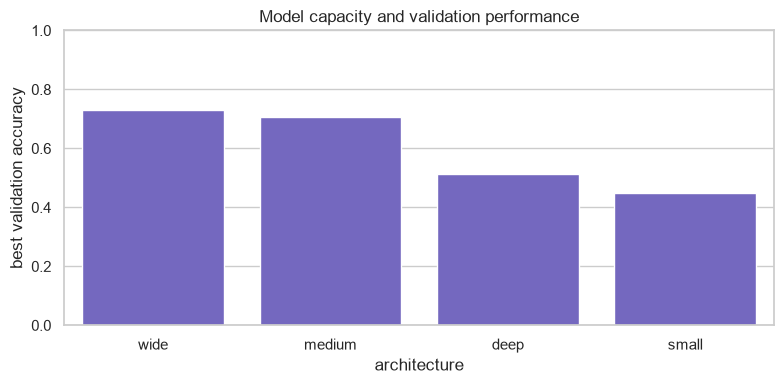

🏃 View run mlp-architecture-small at: http://127.0.0.1:5000/#/experiments/1/runs/12fe8f5fa88e4ef3b7629a54ed2cf08e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-medium at: http://127.0.0.1:5000/#/experiments/1/runs/b2f8a5e6975e4e7ea94c7aab2a5d2556
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-wide at: http://127.0.0.1:5000/#/experiments/1/runs/c94bf47b64294a048ea6743a525b855b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run mlp-architecture-deep at: http://127.0.0.1:5000/#/experiments/1/runs/74c5a07e59cd4356a76509a6dccac31f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [ ]:
architectures = {
    "small": (8,),
    "medium": (32, 16),
    "wide": (128,),
    "deep": (64, 32, 16),
}

capacity_results = []
capacity_histories = {}
capacity_models = {}

for name, hidden_dims in architectures.items():
    capacity_model, capacity_history, best_epoch_capacity = fit_experiment(
        hidden_dims=hidden_dims,
        lr=1e-4,
        epochs=35,
    )
    capacity_histories[name] = capacity_history
    capacity_models[name] = capacity_model
    capacity_results.append(
        {
            "architecture": name,
            "hidden_dims": hidden_dims,
            "parameters": count_parameters(capacity_model),
            "best_epoch": best_epoch_capacity,
            "best_validation_accuracy": max(capacity_history["val_acc"]),
            "final_validation_accuracy": capacity_history["val_acc"][-1],
        }
    )

capacity_table = pd.DataFrame(capacity_results).sort_values(
    "best_validation_accuracy",
    ascending=False,
)
display(capacity_table)

plt.figure(figsize=(8, 4))
sns.barplot(
    data=capacity_table,
    x="architecture",
    y="best_validation_accuracy",
    color="slateblue",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.title("Model capacity and validation performance")
plt.tight_layout()
plt.show()

for name, hidden_dims in architectures.items():
    architecture_history = capacity_histories[name]
    architecture_series = {
        "train_loss": architecture_history["train_loss"],
        "validation_loss": architecture_history["val_loss"],
        "train_accuracy": architecture_history["train_acc"],
        "validation_accuracy": architecture_history["val_acc"],
    }
    log_mlflow_training_run(
        run_name=f"mlp-architecture-{name}",
        params={
            "framework": "pytorch",
            "architecture": name,
            "hidden_dims": str(hidden_dims),
            "requested_epochs": 35,
            "actual_epochs": len(architecture_history["train_loss"]),
            "best_epoch": next(
                row["best_epoch"]
                for row in capacity_results
                if row["architecture"] == name
            ),
            "learning_rate": 1e-3,
            "random_state": RANDOM_STATE,
        },
        series=architecture_series,
        final_metrics={
            "best_validation_accuracy": max(architecture_history["val_acc"]),
            "best_validation_loss": min(architecture_history["val_loss"]),
        },
        model=capacity_models[name],
        model_type="pytorch",
    )

### results table

| Architecture         | Parameters | Train score | Validation score |
| -------------------- | ---------: | ----------: | ---------------: |
| p → 8 → K            |            |             |                  |
| p → 32 → 16 → K      |            |             |                  |
| p → 128 → K          |            |             |                  |
| p → 64 → 32 → 16 → K |            |             |                  |


# Part XIV — Deliberate overfitting


## 29. Build an oversized model

Try something intentionally excessive for the dataset:

```text
p → 256 → 128 → 64 → K
```

Train for more epochs than necessary.

Observe:

$$
training\ loss \downarrow
$$

while validation loss may eventually:

$$
validation\ loss \uparrow
$$


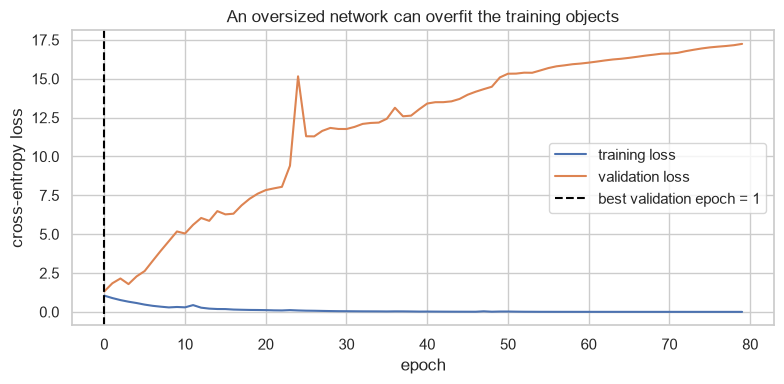

Best validation epoch: 1
Final training loss: 0.0014305286843325565
Final validation loss: 17.24419010602511
🏃 View run mlp-oversized-80-epochs at: http://127.0.0.1:5000/#/experiments/1/runs/2dca15dd75f8406bb1261fa24ba00c39
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'2dca15dd75f8406bb1261fa24ba00c39'

In [ ]:
oversized_model, oversized_history, oversized_best_epoch = fit_experiment(
    hidden_dims=(256, 128, 64), lr=1e-3, epochs=80
)

plt.figure(figsize=(8, 4))
plt.plot(oversized_history["train_loss"], label="training loss")
plt.plot(oversized_history["val_loss"], label="validation loss")
plt.axvline(
    oversized_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best validation epoch = {oversized_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("An oversized network can overfit the training objects")
plt.legend()
plt.tight_layout()
plt.show()

print("Best validation epoch:", oversized_best_epoch)
print("Final training loss:", oversized_history["train_loss"][-1])
print("Final validation loss:", oversized_history["val_loss"][-1])

log_mlflow_training_run(
    run_name="mlp-oversized-80-epochs",
    params={
        "framework": "pytorch",
        "architecture": "256,128,64",
        "requested_epochs": 80,
        "actual_epochs": len(oversized_history["train_loss"]),
        "best_epoch": oversized_best_epoch,
        "learning_rate": 1e-3,
        "random_state": RANDOM_STATE,
    },
    series={
        "train_loss": oversized_history["train_loss"],
        "validation_loss": oversized_history["val_loss"],
        "train_accuracy": oversized_history["train_acc"],
        "validation_accuracy": oversized_history["val_acc"],
    },
    final_metrics={
        "best_validation_accuracy": max(oversized_history["val_acc"]),
        "best_validation_loss": min(oversized_history["val_loss"]),
    },
    model=oversized_model,
    model_type="pytorch",
)

# Part XV — Regularization


## 30. Weight decay


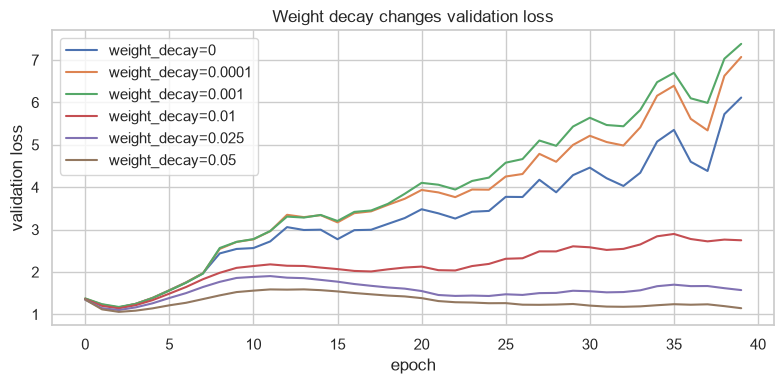

In [ ]:
weight_decay_values = [0.0, 1e-4, 1e-3, 0.01, 0.025, 0.05]
weight_decay_results = {}

for weight_decay in weight_decay_values:
    _, history_wd, best_epoch_wd = fit_experiment(
        weight_decay=weight_decay,
        lr=1e-3,
        epochs=40,
    )
    weight_decay_results[weight_decay] = {
        "history": history_wd,
        "best_epoch": best_epoch_wd,
    }

plt.figure(figsize=(8, 4))
for weight_decay, result in weight_decay_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"weight_decay={weight_decay:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Weight decay changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 31. Dropout


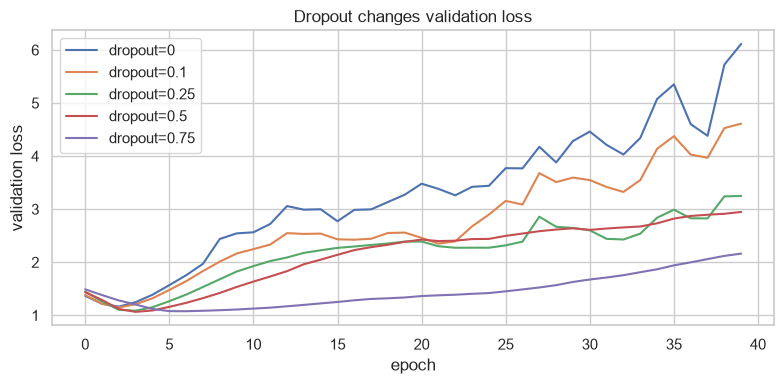

In [ ]:
dropout_values = [0.0, 0.1, 0.25, 0.5, 0.75]
dropout_results = {}

for dropout_rate in dropout_values:
    _, history_dropout, best_epoch_dropout = fit_experiment(
        dropout=dropout_rate,
        lr=1e-3,
        epochs=40,
    )
    dropout_results[dropout_rate] = {
        "history": history_dropout,
        "best_epoch": best_epoch_dropout,
    }

plt.figure(figsize=(8, 4))
for dropout_rate, result in dropout_results.items():
    plt.plot(
        result["history"]["val_loss"],
        label=f"dropout={dropout_rate:g}",
    )

plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Dropout changes validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 32. Early stopping


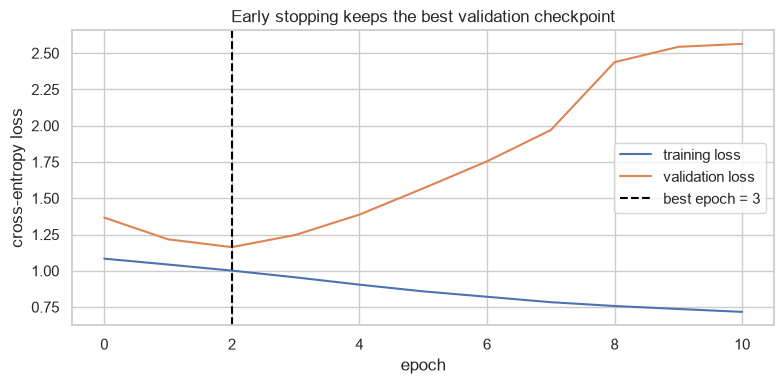

Epochs actually trained: 11
Best validation epoch: 3
🏃 View run mlp-early-stopping at: http://127.0.0.1:5000/#/experiments/1/runs/561110fd525e4304b34d7e96136d5fdf
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'561110fd525e4304b34d7e96136d5fdf'

In [ ]:
early_stop_model, early_stop_history, early_stop_best_epoch = fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    epochs=100,
    patience=8,
)

plt.figure(figsize=(8, 4))
plt.plot(early_stop_history["train_loss"], label="training loss")
plt.plot(early_stop_history["val_loss"], label="validation loss")
plt.axvline(
    early_stop_best_epoch - 1,
    color="black",
    linestyle="--",
    label=f"best epoch = {early_stop_best_epoch}",
)
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Early stopping keeps the best validation checkpoint")
plt.legend()
plt.tight_layout()
plt.show()

print("Epochs actually trained:", len(early_stop_history["train_loss"]))
print("Best validation epoch:", early_stop_best_epoch)

log_mlflow_training_run(
    run_name="mlp-early-stopping",
    params={
        "framework": "pytorch",
        "architecture": "32,16",
        "requested_epochs": 100,
        "actual_epochs": len(early_stop_history["train_loss"]),
        "best_epoch": early_stop_best_epoch,
        "patience": 8,
        "learning_rate": 1e-3,
        "random_state": RANDOM_STATE,
    },
    series={
        "train_loss": early_stop_history["train_loss"],
        "validation_loss": early_stop_history["val_loss"],
        "train_accuracy": early_stop_history["train_acc"],
        "validation_accuracy": early_stop_history["val_acc"],
    },
    final_metrics={
        "best_validation_accuracy": max(early_stop_history["val_acc"]),
        "best_validation_loss": min(early_stop_history["val_loss"]),
    },
    model=early_stop_model,
    model_type="pytorch",
)

## 33. Compare regularization strategies

| Model            | Dropout | Weight decay | Early stopping | Validation score |
| ---------------- | ------: | -----------: | -------------: | ---------------: |
| Baseline         |         |              |                |                  |
| + Weight decay   |         |              |                |                  |
| + Dropout        |         |              |                |                  |
| + Early stopping |         |              |                |                  |


,strategy,best_epoch,best_val_loss,best_val_accuracy
0,baseline,3,1.162903,0.794872
1,weight decay 1e-4,3,1.160478,0.794872
2,dropout 0.25,4,1.086635,0.794872
3,early stopping,3,1.162903,0.730769


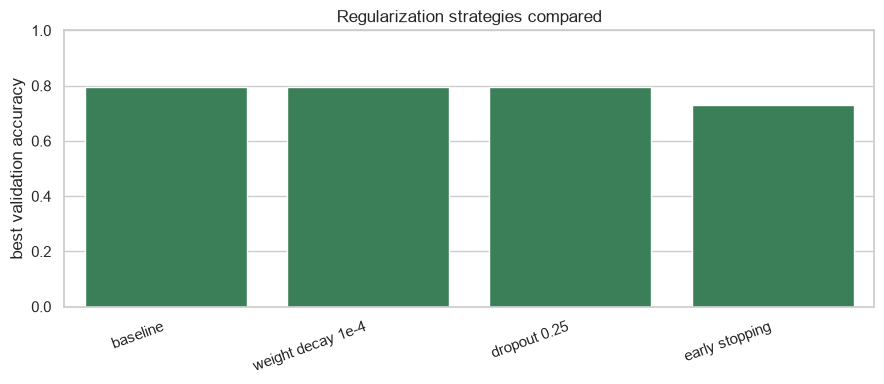

In [ ]:
def best_validation_summary(history):
    best_index = int(np.argmin(history["val_loss"]))
    return {
        "best_epoch": best_index + 1,
        "best_val_loss": history["val_loss"][best_index],
        "best_val_accuracy": max(history["val_acc"]),
    }


regularization_summary = pd.DataFrame(
    [
        {
            "strategy": "baseline",
            **best_validation_summary(learning_rate_results[1e-3]["history"]),
        },
        {
            "strategy": "weight decay 1e-4",
            **best_validation_summary(weight_decay_results[1e-4]["history"]),
        },
        {
            "strategy": "dropout 0.25",
            **best_validation_summary(dropout_results[0.25]["history"]),
        },
        {
            "strategy": "early stopping",
            **best_validation_summary(early_stop_history),
        },
    ]
)

display(regularization_summary)

plt.figure(figsize=(9, 4))
sns.barplot(
    data=regularization_summary,
    x="strategy",
    y="best_val_accuracy",
    color="seagreen",
)
plt.ylim(0, 1)
plt.ylabel("best validation accuracy")
plt.xlabel("")
plt.title("Regularization strategies compared")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Part XVI — Final test evaluation


In [ ]:
best_model = early_stop_model

test_loss, test_acc = evaluate(
    best_model,
    test_loader,
    criterion,
    DEVICE,
)

print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 1.0319296247080754
Test accuracy: 0.5


## 34. Detailed classification metrics


              precision    recall  f1-score   support

          m0      0.424     0.962     0.588        26
          m1      0.692     0.429     0.529        21
          m2      1.000     0.138     0.242        29

    accuracy                          0.500        76
   macro avg      0.705     0.509     0.453        76
weighted avg      0.718     0.500     0.440        76



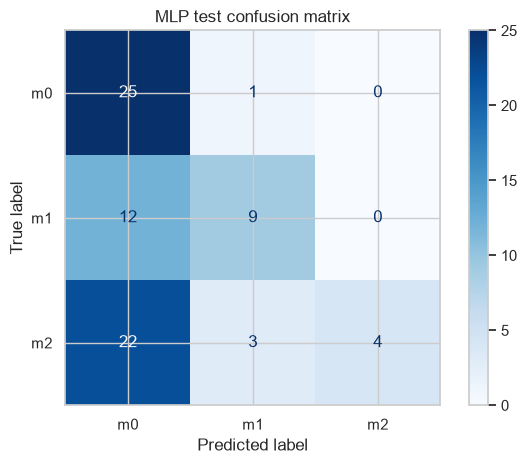

In [ ]:
best_model.eval()
all_logits = []
all_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        all_logits.append(best_model(X_batch.to(DEVICE)).cpu())
        all_targets.append(y_batch.cpu())

test_logits = torch.cat(all_logits).numpy()
y_true = torch.cat(all_targets).numpy()
y_pred = test_logits.argmax(axis=1)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=3,
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
)
plt.title("MLP test confusion matrix")
plt.tight_layout()
plt.show()

# Part XVII — Compare with classical models


## 35. Logistic Regression baseline

A neural network is not automatically better than a simpler model.


In [ ]:
logreg = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE,
)
logreg.fit(X_train_scaled, y_train)
pred_logreg = logreg.predict(X_test_scaled)

print(
    "Logistic regression balanced accuracy:",
    balanced_accuracy_score(y_test, pred_logreg),
)
print("Logistic regression macro F1:", f1_score(y_test, pred_logreg, average="macro"))

Logistic regression balanced accuracy: 0.7858405961854237
Logistic regression macro F1: 0.7889484443156759


## 36. XGBoost baseline and an Optuna hyperparameter search

XGBoost builds trees sequentially, with each new tree correcting errors made by earlier trees. Instead of evaluating every point in a large Cartesian grid, Optuna proposes promising configurations based on previous trials.

The search explores:

- `n_estimators`: number of boosting trees;
- `max_depth`: maximum depth of each tree;
- `learning_rate`: contribution of each new tree;
- `min_child_weight`: minimum amount of data needed for a child split;
- `subsample` and `colsample_bytree`: row and feature subsampling;
- `gamma` and `reg_lambda`: additional regularization.

Each trial is evaluated with three stratified group-aware folds using macro F1. The held-out validation and test sets are not used by Optuna. Twenty trials provide a compact teaching-time search budget; students can increase this value for a more exhaustive analysis.


Completed Optuna trials: 20
Best XGBoost parameters: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.015683938258826146, 'min_child_weight': 1, 'subsample': 0.7, 'colsample_bytree': 1.0, 'gamma': 0.3473713284255278, 'reg_lambda': 2.1522561249728924}
Best group-CV macro F1: 0.791


,number,value
17,17,0.790665
6,6,0.786641
14,14,0.786287
8,8,0.778515
5,5,0.778223
9,9,0.776805
18,18,0.773922
10,10,0.773855
19,19,0.773451
1,1,0.772110


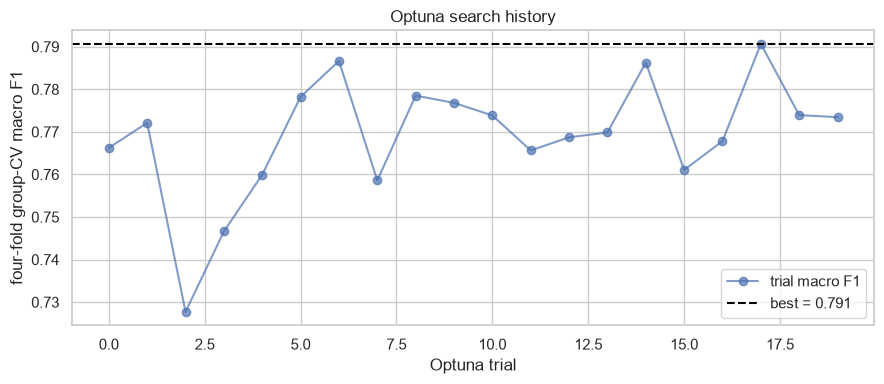

Selected XGBoost validation balanced accuracy: 0.7488536155202822
Selected XGBoost validation macro F1: 0.7523412698412698
Selected XGBoost test balanced accuracy: 0.6028167235063786
Selected XGBoost test macro F1: 0.6045262207008034
🏃 View run xgboost-optuna-best at: http://127.0.0.1:5000/#/experiments/1/runs/a845d5fdbb414801a47917668a83926b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


'a845d5fdbb414801a47917668a83926b'

In [ ]:
xgb_train_y = y_train.map(class_to_index).to_numpy(dtype=np.int64)
xgb_val_y = y_val.map(class_to_index).to_numpy(dtype=np.int64)

xgb_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE + 2,
)
xgb_cv_splits = list(
    xgb_cv.split(
        X_train_imputed,
        xgb_train_y,
        groups=groups_train.to_numpy(),
    )
)

optuna.logging.set_verbosity(optuna.logging.WARNING)


def xgb_objective(trial):
    trial_params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0, step=0.1),
        "gamma": trial.suggest_float("gamma", 0.0, 0.5),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

    fold_scores = []
    for fold_train_idx, fold_val_idx in xgb_cv_splits:
        fold_model = XGBClassifier(
            objective="multi:softprob",
            num_class=n_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0,
            **trial_params,
        )
        fold_model.fit(
            X_train_imputed[fold_train_idx],
            xgb_train_y[fold_train_idx],
        )
        fold_pred = fold_model.predict(X_train_imputed[fold_val_idx]).astype(int)
        fold_scores.append(
            f1_score(
                xgb_train_y[fold_val_idx],
                fold_pred,
                average="macro",
            )
        )

    return float(np.mean(fold_scores))


xgb_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
xgb_study.optimize(
    xgb_objective,
    n_trials=20,
    show_progress_bar=False,
)

print("Completed Optuna trials:", len(xgb_study.trials))
print("Best XGBoost parameters:", xgb_study.best_params)
print(f"Best group-CV macro F1: {xgb_study.best_value:.3f}")

optuna_results = (
    xgb_study.trials_dataframe()
    .query("state == 'COMPLETE'")
    .sort_values("value", ascending=False)[["number", "value"]]
    .head(10)
)
display(optuna_results)

all_trial_values = [
    trial.value for trial in xgb_study.trials if trial.value is not None
]
plt.figure(figsize=(9, 4))
plt.plot(all_trial_values, marker="o", alpha=0.7, label="trial macro F1")
plt.axhline(
    xgb_study.best_value,
    color="black",
    linestyle="--",
    label=f"best = {xgb_study.best_value:.3f}",
)
plt.xlabel("Optuna trial")
plt.ylabel("four-fold group-CV macro F1")
plt.title("Optuna search history")
plt.legend()
plt.tight_layout()
plt.show()

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=n_classes,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=0,
    **xgb_study.best_params,
)
xgb_model.fit(X_train_imputed, xgb_train_y)

pred_xgb_val_codes = xgb_model.predict(X_val_imputed).astype(int)
pred_xgb_val = np.asarray(class_names)[pred_xgb_val_codes]

print(
    "Selected XGBoost validation balanced accuracy:",
    balanced_accuracy_score(y_val, pred_xgb_val),
)
print(
    "Selected XGBoost validation macro F1:",
    f1_score(y_val, pred_xgb_val, average="macro"),
)

pred_xgb_codes = xgb_model.predict(X_test_imputed).astype(int)
pred_xgb = np.asarray(class_names)[pred_xgb_codes]

print(
    "Selected XGBoost test balanced accuracy:",
    balanced_accuracy_score(y_test, pred_xgb),
)
print("Selected XGBoost test macro F1:", f1_score(y_test, pred_xgb, average="macro"))

xgb_validation_metrics = {
    "validation_balanced_accuracy": balanced_accuracy_score(y_val, pred_xgb_val),
    "validation_macro_f1": f1_score(y_val, pred_xgb_val, average="macro"),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, pred_xgb),
    "test_macro_f1": f1_score(y_test, pred_xgb, average="macro"),
    "best_group_cv_macro_f1": xgb_study.best_value,
}
log_mlflow_training_run(
    run_name="xgboost-optuna-best",
    params={
        "framework": "xgboost",
        "search_method": "Optuna TPE",
        "search_trials": len(xgb_study.trials),
        "random_state": RANDOM_STATE,
        **xgb_study.best_params,
    },
    final_metrics=xgb_validation_metrics,
    model=xgb_model,
    model_type="xgboost",
)

## 37. Final comparison

| Model               | Balanced accuracy | Macro F1 | Notes                     |
| ------------------- | ----------------: | -------: | ------------------------- |
| Logistic Regression |                   |          | linear baseline           |
| XGBoost             |                   |          | tuned tree-boosting model |
| MLP                 |                   |          | neural-network model      |


,model,balanced_accuracy,macro_f1
0,Logistic Regression,0.785841,0.788948
1,XGBoost,0.602817,0.604526
2,MLP,0.509347,0.453357


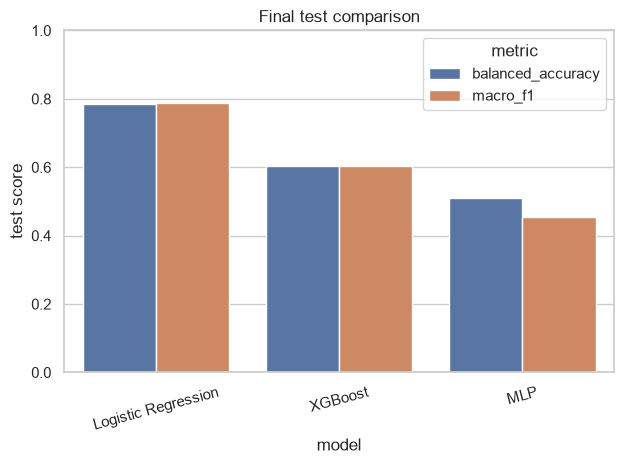

In [ ]:
pred_mlp_labels = np.asarray(class_names)[y_pred]

comparison = (
    pd.DataFrame(
        [
            {
                "model": "MLP",
                "balanced_accuracy": balanced_accuracy_score(y_test, pred_mlp_labels),
                "macro_f1": f1_score(y_test, pred_mlp_labels, average="macro"),
            },
            {
                "model": "Logistic Regression",
                "balanced_accuracy": balanced_accuracy_score(y_test, pred_logreg),
                "macro_f1": f1_score(y_test, pred_logreg, average="macro"),
            },
            {
                "model": "XGBoost",
                "balanced_accuracy": balanced_accuracy_score(y_test, pred_xgb),
                "macro_f1": f1_score(y_test, pred_xgb, average="macro"),
            },
        ]
    )
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(comparison)

comparison_plot = comparison.melt(
    id_vars="model",
    value_vars=["balanced_accuracy", "macro_f1"],
    var_name="metric",
    value_name="score",
)
sns.barplot(data=comparison_plot, x="model", y="score", hue="metric")
plt.ylim(0, 1)
plt.ylabel("test score")
plt.title("Final test comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Discussion

- Did the MLP outperform the simpler models?
- Was the performance gain worth the added complexity?
- Which model is easier to interpret?
- Which model would you deploy for this biological problem?


# Part XVIII — TensorFlow / Keras comparison


## 38. Same architecture in Keras

We keep PyTorch as the main teaching framework, then show that the same layer and loss ideas exist in Keras.

On native Windows, TensorFlow 2.11 and later does not use CUDA GPU acceleration. A warning about unavailable TensorFlow GPU support is expected on native Windows; it is not the cause of the dtype error. GPU TensorFlow requires WSL2 or an alternative such as DirectML.


In [ ]:
import tensorflow as tf
from tensorflow import keras

keras_model = keras.Sequential(
    [
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(n_classes),
    ]
)

keras_model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 2,179 (8.51 KB)
 Trainable params: 2,179 (8.51 KB)
 Non-trainable params: 0 (0.00 B)


## 39. Compile and train


In [ ]:
# SparseCategoricalCrossentropy expects integer class codes,
# not the original string labels m0, m1, and m2.
y_train_keras = y_train.map(class_to_index).to_numpy(dtype=np.int64)
y_val_keras = y_val.map(class_to_index).to_numpy(dtype=np.int64)
X_train_keras = np.asarray(X_train_scaled, dtype=np.float32)
X_val_keras = np.asarray(X_val_scaled, dtype=np.float32)

keras_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

history_keras = keras_model.fit(
    X_train_keras,
    y_train_keras,
    validation_data=(X_val_keras, y_val_keras),
    epochs=50,
    batch_size=32,
    verbose=1,
)

keras_series = {
    "train_loss": history_keras.history["loss"],
    "validation_loss": history_keras.history["val_loss"],
    "train_accuracy": history_keras.history["accuracy"],
    "validation_accuracy": history_keras.history["val_accuracy"],
}
log_mlflow_training_run(
    run_name="keras-baseline",
    params={
        "framework": "keras",
        "architecture": "32,16",
        "input_dim": input_dim,
        "n_classes": n_classes,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "epochs": len(keras_series["train_loss"]),
        "batch_size": 32,
        "random_state": RANDOM_STATE,
    },
    series=keras_series,
    final_metrics={
        "final_validation_accuracy": keras_series["validation_accuracy"][-1],
        "best_validation_accuracy": max(keras_series["validation_accuracy"]),
        "best_validation_loss": min(keras_series["validation_loss"]),
    },
    model=keras_model,
    model_type="keras",
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9515 - loss: 0.1885 - val_accuracy: 0.7821 - val_loss: 5.6764
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9559 - loss: 0.1769 - val_accuracy: 0.7821 - val_loss: 6.0938
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9604 - loss: 0.1704 - val_accuracy: 0.7821 - val_loss: 6.3501
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9604 - loss: 0.1660 - val_accuracy: 0.7821 - val_loss: 5.8764
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9559 - loss: 0.1613 - val_accuracy: 0.7821 - val_loss: 5.2934
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9559 - loss: 0.1565 - val_accuracy: 0.7821 - val_loss: 5.5783
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9648 - loss: 0.1521 - val_accuracy: 0.7821 - val_loss: 6.2539
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9648 - loss: 0.1495 - val_accuracy: 0.7821 - val_loss: 6.3639


'b71217d10a2b41fba3da366099b8f4b0'

## 40. PyTorch vs Keras

| Concept       | PyTorch             | Keras                     |
| ------------- | ------------------- | ------------------------- |
| Dense layer   | `nn.Linear`         | `Dense`                   |
| Activation    | `nn.ReLU()`         | `activation="relu"`       |
| Loss          | explicit object     | `compile(loss=...)`       |
| Optimizer     | explicit object     | `compile(optimizer=...)`  |
| Training loop | explicit by default | usually hidden in `fit()` |
| Gradients     | `loss.backward()`   | automatic inside `fit()`  |


## 41. Hometask

Same experiment - different representation. Dataset contains same data, but it uses vgg16 embeddings instead of handcrafted morpho characteristics.

> week6\large_object_vgg3d_embeddings_processed.csv


## Task

Build and evaluate a neural-network classifier for `cell_type` using the VGG3D embedding representation. Compare it with at least one simpler model and explain what the results mean biologically and statistically.

Do not use `sample_group` as a predictive feature. Use it only to construct leakage-safe splits.

## Required sections

### 1. Data inspection and preparation checklist

Since data is the same no need to write detailed report but still - check if everything is in order(just in case)

### 2. Exploratory analysis

Show:

- class counts for `m0`, `m1`, and `m2`;
- the distribution of selected embedding features;
- missingness by feature and by row;
- a two-dimensional t-SNE or UMAP visualization coloured by `cell_type`.

Treat t-SNE/UMAP as exploratory visualizations, not as test-set evaluation.

### 3. Leakage-safe splitting and preprocessing

Create training, validation, and test partitions, be sure that you dont introduce any leakege.

### 4. Baseline and MLP model

Train a simple baseline, such as multinomial logistic regression, followed by a PyTorch MLP

Report training and validation loss and accuracy across epochs.

### 5. Experiments

Perform experiments corresponding to the Week 6 explanations:

- compare at least three learning rates;
- compare at least two network capacities;
- identify possible overfitting from learning curves;
- compare weight decay and dropout;
- demonstrate early stopping;
- explain which configuration you select and why.

Keep the random seed fixed when comparing configurations.

### 6. Classical comparison

Compare the selected MLP with:

- logistic regression;
- XGBoost with a small, validation-only hyperparameter search.

### 7. Evaluation

Evaluate the final selected models on the untouched test partition using:

- balanced accuracy;
- macro F1 score;
- a confusion matrix;
- a short class-by-class error analysis.

Do not select the final model using test performance.

## Questions for the report

1. Did the embedding space show visible separation between the cell types?
2. Which learning rate and architecture performed best, and what evidence supports that choice?
3. Did the MLP overfit? Use the training and validation curves to justify your answer.
4. Which regularization method was most useful?
5. How did the MLP compare with logistic regression and XGBoost?
6. Which cell types were most frequently confused?
7. What additional biological or technical information would help explain the errors?

## Deliverables

- completed notebook;
- short report answering the questions above;
- one table comparing the final models;
- figures for the embedding visualization, learning curves, and confusion matrix;
- a brief statement of limitations and possible next steps.


In [30]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    silhouette_score,
)
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 141026
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
print("Device:", DEVICE)

Device: cpu


In [ ]:
DATA_PATH = Path("week6/large_object_vgg3d_embeddings_processed.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("large_object_vgg3d_embeddings_processed.csv")

df = pd.read_csv(DATA_PATH)
TARGET = "cell_type"
GROUP_COLUMN = "sample_group"
CLASS_NAMES = ["m0", "m1", "m2"]

print("Data path:", DATA_PATH)
print("Shape:", df.shape)
display(df.iloc[:5, :8])

assert TARGET in df.columns and GROUP_COLUMN in df.columns
assert set(df[TARGET].unique()) == set(CLASS_NAMES), df[TARGET].unique()

candidate_cols = [c for c in df.columns if c not in (TARGET, GROUP_COLUMN)]
non_numeric = [c for c in candidate_cols if not pd.api.types.is_numeric_dtype(df[c])]
feature_cols = [c for c in candidate_cols if c not in non_numeric]

df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)
constant_features = [c for c in feature_cols if df[c].nunique(dropna=True) <= 1]
feature_cols = [c for c in feature_cols if c not in constant_features]

row_hash = pd.util.hash_pandas_object(df[feature_cols], index=False)
labels_per_vector = df.groupby(row_hash)[TARGET].nunique()
groups_multi_class = (df.groupby(GROUP_COLUMN)[TARGET].nunique() > 1).sum()
feature_std = df[feature_cols].std()

print("Column names unique:", df.columns.is_unique)
print("Non-numeric columns excluded:", non_numeric)
print("Constant features removed:", len(constant_features))
print("Number of embedding features:", len(feature_cols))
print("Objects:", len(df), "| sample groups:", df[GROUP_COLUMN].nunique())
print("Total missing values:", int(df[feature_cols].isna().sum().sum()))
print("Exact duplicate feature vectors:", int(df.duplicated(subset=feature_cols).sum()))
print(
    "Identical feature vectors with different labels:",
    int((labels_per_vector > 1).sum()),
)
print("Sample groups containing more than one class:", int(groups_multi_class))
print("Feature std range: %.4g - %.4g" % (feature_std.min(), feature_std.max()))
print(
    "Feature value range: %.4g - %.4g"
    % (df[feature_cols].min().min(), df[feature_cols].max().max())
)
display(df[TARGET].value_counts().reindex(CLASS_NAMES).rename("objects").to_frame())
display(
    df[GROUP_COLUMN].value_counts().describe().rename("objects_per_group").to_frame().T
)

Data path: large_object_vgg3d_embeddings_processed.csv
Shape: (381, 130)


,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0


Column names unique: True
Non-numeric columns excluded: []
Constant features removed: 37
Number of embedding features: 91
Objects: 381 | sample groups: 85
Total missing values: 0
Exact duplicate feature vectors: 0
Identical feature vectors with different labels: 0
Sample groups containing more than one class: 0
Feature std range: 0.0003102 - 7.495
Feature value range: 0 - 44.92


,objects
cell_type,
m0,132
m1,104
m2,145


,count,mean,std,min,25%,50%,75%,max
objects_per_group,85.0,4.482353,4.376919,1.0,2.0,3.0,5.0,22.0


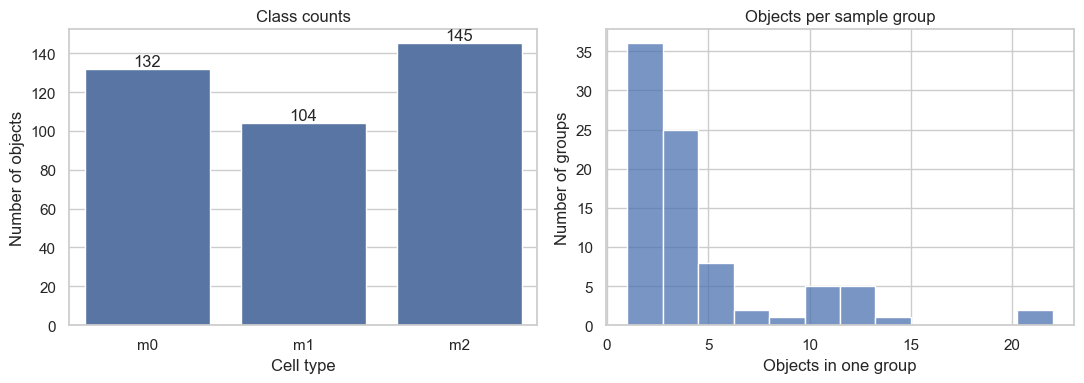

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x=TARGET, order=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Class counts")
axes[0].set_xlabel("Cell type")
axes[0].set_ylabel("Number of objects")
for container in axes[0].containers:
    axes[0].bar_label(container)

sns.histplot(df[GROUP_COLUMN].value_counts(), bins=12, ax=axes[1])
axes[1].set_title("Objects per sample group")
axes[1].set_xlabel("Objects in one group")
axes[1].set_ylabel("Number of groups")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_counts.png", dpi=150)
plt.show()

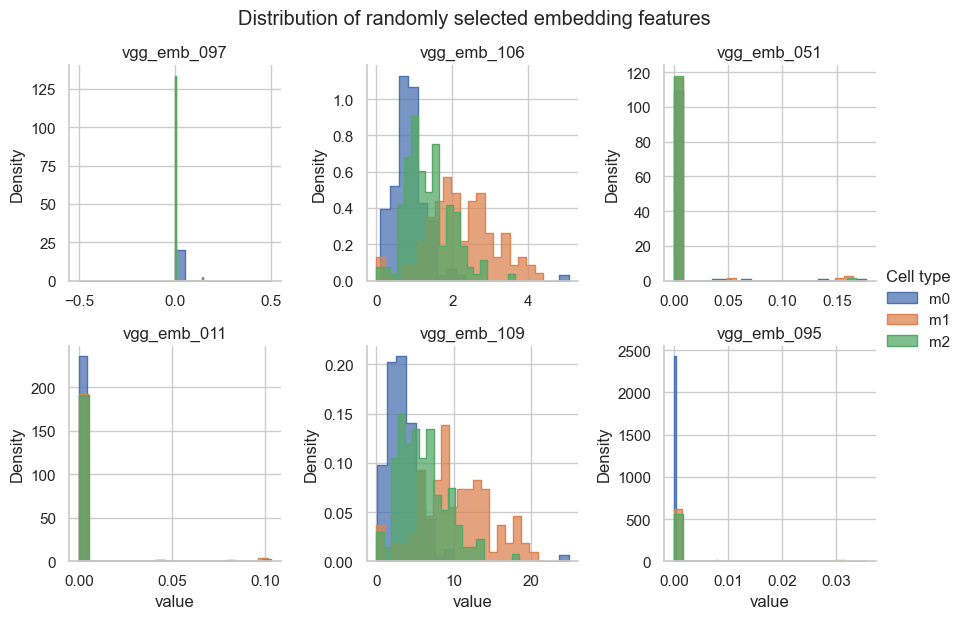

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
plot_features = list(
    rng.choice(feature_cols, size=min(6, len(feature_cols)), replace=False)
)

long_df = df.melt(
    id_vars=[TARGET],
    value_vars=plot_features,
    var_name="feature",
    value_name="value",
)
g = sns.FacetGrid(
    long_df,
    col="feature",
    col_wrap=3,
    hue=TARGET,
    hue_order=CLASS_NAMES,
    sharex=False,
    sharey=False,
    height=3,
)
g.map_dataframe(
    sns.histplot,
    x="value",
    bins=20,
    element="step",
    stat="density",
    common_norm=False,
)
g.add_legend(title="Cell type")
g.set_titles("{col_name}")
g.fig.suptitle("Distribution of randomly selected embedding features", y=1.03)
g.savefig(FIG_DIR / "feature_distributions.png", dpi=150)
plt.show()

In [ ]:
missing_by_feature = df[feature_cols].isna().sum()
missing_by_row = df[feature_cols].isna().sum(axis=1)

print(
    "Features with missing values:",
    int((missing_by_feature > 0).sum()),
    "of",
    len(feature_cols),
)
print("Rows with missing values:", int((missing_by_row > 0).sum()), "of", len(df))

if missing_by_feature.sum() > 0:
    display(
        missing_by_feature[missing_by_feature > 0]
        .sort_values(ascending=False)
        .head(15)
        .rename("missing")
        .to_frame()
    )
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.histplot(missing_by_feature[missing_by_feature > 0], bins=20, ax=axes[0])
    axes[0].set_title("Missing values per feature")
    axes[0].set_xlabel("missing objects")
    sns.histplot(missing_by_row, bins=20, ax=axes[1])
    axes[1].set_title("Missing values per row")
    axes[1].set_xlabel("missing features")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values: missingness by feature and by row is zero everywhere.")

Features with missing values: 0 of 91
Rows with missing values: 0 of 381
No missing values: missingness by feature and by row is zero everywhere.


Silhouette (class labels) in scaled embedding space: 0.041
Silhouette (class labels) in t-SNE space: 0.066


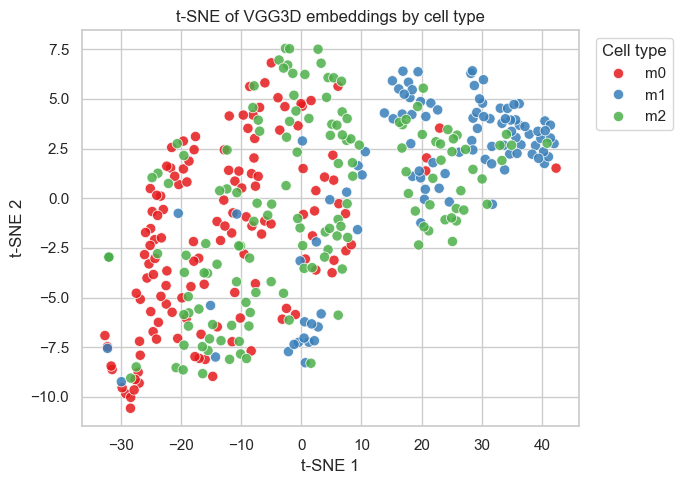

In [ ]:
# Exploratory only: scaling/imputation here are NOT used for modelling.
X_vis = StandardScaler().fit_transform(
    SimpleImputer(strategy="median").fit_transform(df[feature_cols])
)
y_vis = df[TARGET].to_numpy()

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(X_vis)

print(
    "Silhouette (class labels) in scaled embedding space: %.3f"
    % silhouette_score(X_vis, y_vis)
)
print(
    "Silhouette (class labels) in t-SNE space: %.3f" % silhouette_score(X_tsne, y_vis)
)

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=y_vis,
    hue_order=CLASS_NAMES,
    palette="Set1",
    s=55,
    alpha=0.85,
)
plt.title("t-SNE of VGG3D embeddings by cell type")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "tsne_embeddings.png", dpi=150)
plt.show()

In [ ]:
X = df[feature_cols].copy()
y = df[TARGET].copy()
groups = df[GROUP_COLUMN].copy()


def split_quality(test_indices, y_values, target_fraction):
    overall = y_values.value_counts(normalize=True).sort_index()
    test_prop = (
        y_values.iloc[test_indices]
        .value_counts(normalize=True)
        .reindex(overall.index)
        .fillna(0)
    )
    size_error = abs(len(test_indices) / len(y_values) - target_fraction)
    return size_error + np.abs(test_prop - overall).sum()


outer_splits = list(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
        X, y, groups=groups
    )
)
outer_fold = min(
    range(len(outer_splits)), key=lambda i: split_quality(outer_splits[i][1], y, 0.20)
)
train_full_idx, test_idx = outer_splits[outer_fold]

X_train_full, X_test = X.iloc[train_full_idx], X.iloc[test_idx]
y_train_full, y_test = y.iloc[train_full_idx], y.iloc[test_idx]
groups_train_full, groups_test = groups.iloc[train_full_idx], groups.iloc[test_idx]

inner_splits = list(
    StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE + 1).split(
        X_train_full, y_train_full, groups=groups_train_full
    )
)
inner_fold = min(
    range(len(inner_splits)),
    key=lambda i: split_quality(inner_splits[i][1], y_train_full, 0.25),
)
train_idx, val_idx = inner_splits[inner_fold]

X_train, X_val = X_train_full.iloc[train_idx], X_train_full.iloc[val_idx]
y_train, y_val = y_train_full.iloc[train_idx], y_train_full.iloc[val_idx]
groups_train, groups_val = (
    groups_train_full.iloc[train_idx],
    groups_train_full.iloc[val_idx],
)

assert not set(groups_train) & set(groups_val)
assert not set(groups_train) & set(groups_test)
assert not set(groups_val) & set(groups_test)
assert set(y_train) == set(y_val) == set(y_test) == set(CLASS_NAMES)

split_summary = pd.DataFrame(
    {
        "objects": [len(X_train), len(X_val), len(X_test)],
        "groups": [groups_train.nunique(), groups_val.nunique(), groups_test.nunique()],
        **{c: [(s == c).sum() for s in (y_train, y_val, y_test)] for c in CLASS_NAMES},
    },
    index=["train", "validation", "test"],
)
display(split_summary)
print("Group overlap between partitions: none")

,objects,groups,m0,m1,m2
train,223,52,73,59,91
validation,73,16,25,20,28
test,85,17,34,25,26


Group overlap between partitions: none


In [ ]:
# Imputer and scaler are fitted on the training partition only.
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

class_to_index = {name: i for i, name in enumerate(CLASS_NAMES)}
y_train_np = y_train.map(class_to_index).to_numpy(dtype=np.int64)
y_val_np = y_val.map(class_to_index).to_numpy(dtype=np.int64)
y_test_np = y_test.map(class_to_index).to_numpy(dtype=np.int64)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_np)
y_val_t = torch.tensor(y_val_np)
y_test_t = torch.tensor(y_test_np)

BATCH_SIZE = 32
train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False
)

input_dim = X_train_scaled.shape[1]
n_classes = len(CLASS_NAMES)
print("Class mapping:", class_to_index)
print("Shapes (train/val/test):", X_train_t.shape, X_val_t.shape, X_test_t.shape)
print(
    "Missing values after imputation:",
    int(
        np.isnan(X_train_scaled).sum()
        + np.isnan(X_val_scaled).sum()
        + np.isnan(X_test_scaled).sum()
    ),
)

Class mapping: {'m0': 0, 'm1': 1, 'm2': 2}
Shapes (train/val/test): torch.Size([223, 91]) torch.Size([73, 91]) torch.Size([85, 91])
Missing values after imputation: 0


In [ ]:
# Baseline: multinomial logistic regression, C selected on the validation partition only.
logreg_rows = []
for C in [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]:
    model_c = LogisticRegression(C=C, max_iter=5000, random_state=RANDOM_STATE)
    model_c.fit(X_train_scaled, y_train_np)
    pred_c = model_c.predict(X_val_scaled)
    logreg_rows.append(
        {
            "C": C,
            "val_balanced_accuracy": balanced_accuracy_score(y_val_np, pred_c),
            "val_macro_f1": f1_score(y_val_np, pred_c, average="macro"),
        }
    )

logreg_table = (
    pd.DataFrame(logreg_rows)
    .sort_values(["val_macro_f1", "val_balanced_accuracy"], ascending=False)
    .reset_index(drop=True)
)
display(logreg_table)

best_C = float(logreg_table.loc[0, "C"])
logreg = LogisticRegression(C=best_C, max_iter=5000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train_np)
print("Selected C:", best_C)

,C,val_balanced_accuracy,val_macro_f1
0,1.0000,0.672381,0.679153
1,0.1000,0.661905,0.668864
2,10.0000,0.639524,0.645127
3,0.0100,0.621429,0.626947
4,0.0010,0.544762,0.551967
5,0.0001,0.366190,0.283123


Selected C: 1.0


In [ ]:
criterion = nn.CrossEntropyLoss()


class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()
        layers = []
        current_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim
        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X_batch.size(0)
        total_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        total_samples += X_batch.size(0)
    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, total_correct, total_samples = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        total_loss += loss.item() * X_batch.size(0)
        total_correct += (logits.argmax(dim=1) == y_batch).sum().item()
        total_samples += X_batch.size(0)
    return total_loss / total_samples, total_correct / total_samples


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    weight_decay=0.0,
    dropout=0.0,
    epochs=60,
    patience=None,
):
    torch.manual_seed(RANDOM_STATE)
    model = FlexibleMLP(
        input_dim, n_classes, hidden_dims=hidden_dims, dropout=dropout
    ).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_state, best_val_loss, best_epoch, no_improve = None, np.inf, epochs, 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, DEVICE
        )
        val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            no_improve = 0
        else:
            no_improve += 1
        if patience is not None and no_improve >= patience:
            break

    model.load_state_dict(best_state)
    return model, history, best_epoch


def summarize(history, best_epoch):
    i = best_epoch - 1
    return {
        "best_epoch": best_epoch,
        "epochs_run": len(history["train_loss"]),
        "train_loss": history["train_loss"][i],
        "val_loss": history["val_loss"][i],
        "train_acc": history["train_acc"][i],
        "val_acc": history["val_acc"][i],
        "final_train_loss": history["train_loss"][-1],
        "final_val_loss": history["val_loss"][-1],
        "final_train_acc": history["train_acc"][-1],
        "final_val_acc": history["val_acc"][-1],
    }


def plot_history(history, best_epoch, title, filename=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].axvline(
        best_epoch - 1,
        color="black",
        linestyle="--",
        label=f"best epoch = {best_epoch}",
    )
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].axvline(best_epoch - 1, color="black", linestyle="--")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    if filename:
        plt.savefig(FIG_DIR / filename, dpi=150)
    plt.show()


def run_grid(configs, epochs=60, patience=None):
    results = {}
    for name, cfg in configs.items():
        model, history, best_epoch = fit_experiment(
            epochs=epochs, patience=patience, **cfg
        )
        results[name] = {
            "model": model,
            "history": history,
            "best_epoch": best_epoch,
            "config": cfg,
            "summary": summarize(history, best_epoch),
        }
    return results


def results_table(results):
    rows = [
        {"config": name, "parameters": count_parameters(r["model"]), **r["summary"]}
        for name, r in results.items()
    ]
    return pd.DataFrame(rows).sort_values(["val_loss"]).reset_index(drop=True)


def plot_grid_curves(results, title, filename=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    colors = sns.color_palette("tab10", len(results))
    for color, (name, r) in zip(colors, results.items()):
        axes[0].plot(r["history"]["train_loss"], color=color, linestyle="--", alpha=0.7)
        axes[0].plot(r["history"]["val_loss"], color=color, label=name)
        axes[1].plot(r["history"]["val_acc"], color=color, label=name)
    axes[0].set_title("Loss (dashed = train, solid = validation)")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy")
    axes[0].legend(fontsize=8)
    axes[1].set_title("Validation accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    if filename:
        plt.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

,train_loss,val_loss,train_acc,val_acc
epoch,,,,
5,0.9335,1.0493,0.5785,0.5890
10,0.8011,1.1068,0.6233,0.6164
15,0.7542,1.1984,0.6413,0.5616
20,0.7119,1.1768,0.6368,0.5890
25,0.6907,1.1782,0.6592,0.6164
30,0.6739,1.1550,0.6637,0.6164
35,0.6643,1.1502,0.6771,0.6164
40,0.6511,1.1454,0.6861,0.6301
45,0.6431,1.1591,0.6906,0.6438


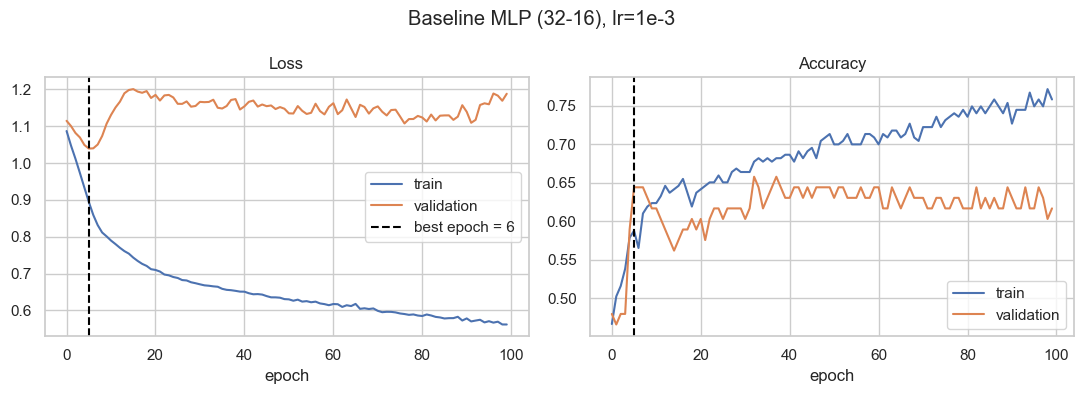

In [ ]:
baseline_model, baseline_history, baseline_best_epoch = fit_experiment(
    hidden_dims=(32, 16), lr=1e-3, epochs=100
)

baseline_log = pd.DataFrame(baseline_history)
baseline_log.index = np.arange(1, len(baseline_log) + 1)
baseline_log.index.name = "epoch"
display(baseline_log.iloc[4::5].round(4))
plot_history(
    baseline_history,
    baseline_best_epoch,
    "Baseline MLP (32-16), lr=1e-3",
    "learning_curves_baseline.png",
)

,config,parameters,best_epoch,epochs_run,train_loss,val_loss,train_acc,val_acc,final_train_loss,final_val_loss,final_train_acc,final_val_acc
0,lr=0.0001,3523,57,60,0.8442,1.0064,0.6099,0.6301,0.8346,1.0075,0.6233,0.6575
1,lr=0.001,3523,6,60,0.8947,1.0394,0.5874,0.6438,0.6142,1.1527,0.7085,0.6438
2,lr=0.1,3523,3,60,1.0645,1.0725,0.4081,0.3836,1.0702,1.0900,0.4081,0.3836
3,lr=0.01,3523,1,60,1.0097,1.1808,0.4978,0.6027,0.4785,18.9896,0.7668,0.5342


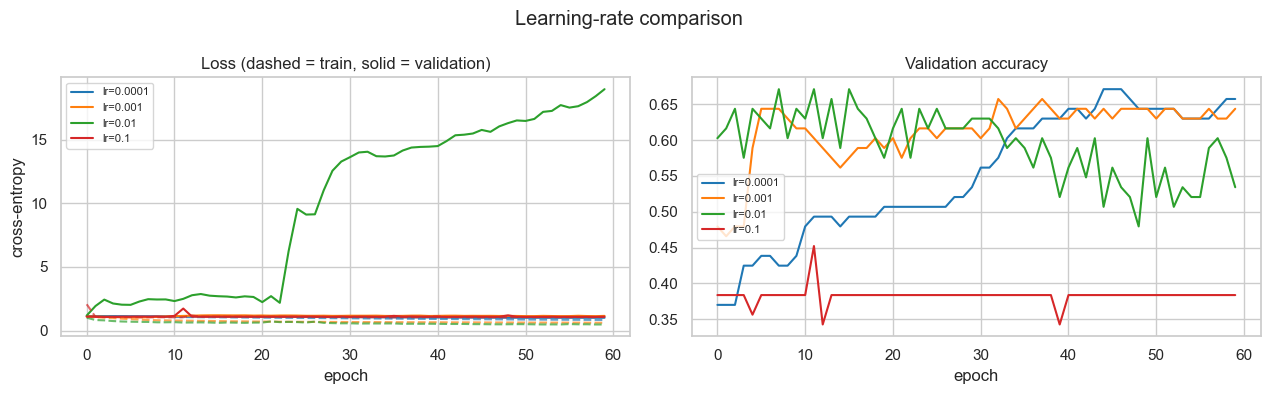

Selected learning rate (lowest validation loss): 0.0001


In [ ]:
lr_results = run_grid(
    {f"lr={lr:g}": {"lr": lr} for lr in [1e-4, 1e-3, 1e-2, 1e-1]}, epochs=60
)
lr_table = results_table(lr_results)
display(lr_table.round(4))
plot_grid_curves(lr_results, "Learning-rate comparison", "learning_rate_comparison.png")

best_lr = lr_results[lr_table.loc[0, "config"]]["config"]["lr"]
print("Selected learning rate (lowest validation loss):", best_lr)

,config,parameters,best_epoch,epochs_run,train_loss,val_loss,train_acc,val_acc,final_train_loss,final_val_loss,final_train_acc,final_val_acc,val_loss_rise_after_best,final_acc_gap
0,small (16),1523,32,100,0.8974,0.9430,0.5650,0.5616,0.7954,1.0064,0.6143,0.6301,0.0633,-0.0158
1,medium (64-32),8067,46,100,0.8141,0.9714,0.6368,0.6027,0.7139,1.0544,0.6413,0.5890,0.0830,0.0522
2,deep (256-128-64),64899,12,100,0.9180,0.9763,0.5336,0.5342,0.6043,1.5137,0.7265,0.6575,0.5373,0.0689
3,wide (256),24323,8,100,0.9004,1.3339,0.5785,0.6027,0.6595,1.8530,0.6816,0.6301,0.5191,0.0515


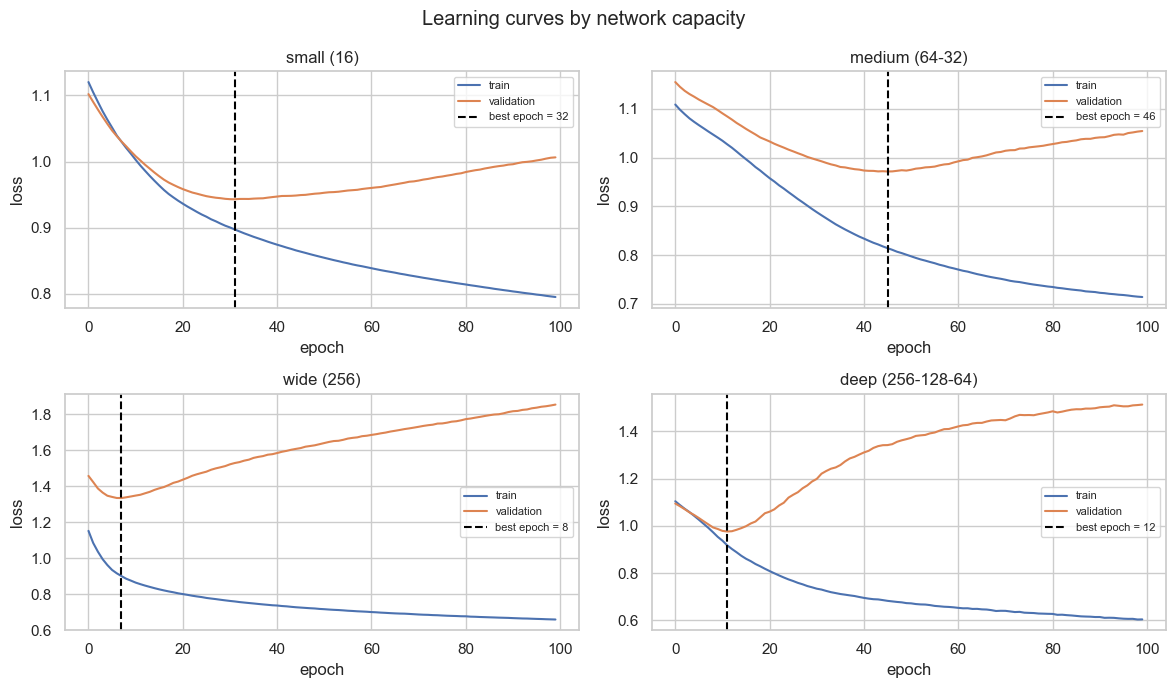

Selected architecture (lowest validation loss): small (16) (16,)


In [ ]:
architectures = {
    "small (16)": (16,),
    "medium (64-32)": (64, 32),
    "wide (256)": (256,),
    "deep (256-128-64)": (256, 128, 64),
}
cap_results = run_grid(
    {
        name: {"hidden_dims": dims, "lr": best_lr}
        for name, dims in architectures.items()
    },
    epochs=100,
)
cap_table = results_table(cap_results)
cap_table["val_loss_rise_after_best"] = (
    cap_table["final_val_loss"] - cap_table["val_loss"]
)
cap_table["final_acc_gap"] = cap_table["final_train_acc"] - cap_table["final_val_acc"]
display(cap_table.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=False)
for ax, (name, r) in zip(axes.ravel(), cap_results.items()):
    ax.plot(r["history"]["train_loss"], label="train")
    ax.plot(r["history"]["val_loss"], label="validation")
    ax.axvline(
        r["best_epoch"] - 1,
        color="black",
        linestyle="--",
        label=f"best epoch = {r['best_epoch']}",
    )
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend(fontsize=8)
fig.suptitle("Learning curves by network capacity")
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curves_capacity.png", dpi=150)
plt.show()

best_arch_name = cap_table.loc[0, "config"]
best_dims = architectures[best_arch_name]
print("Selected architecture (lowest validation loss):", best_arch_name, best_dims)

,config,parameters,best_epoch,epochs_run,train_loss,val_loss,train_acc,val_acc,final_train_loss,final_val_loss,final_train_acc,final_val_acc
0,wd=0,1523,32,100,0.8974,0.9430,0.565,0.5616,0.7954,1.0064,0.6143,0.6301
1,wd=0.0001,1523,32,100,0.8974,0.9430,0.565,0.5616,0.7954,1.0063,0.6143,0.6301
2,wd=0.001,1523,32,100,0.8975,0.9432,0.565,0.5616,0.7956,1.0064,0.6143,0.6301
3,wd=0.01,1523,32,100,0.8987,0.9436,0.565,0.5479,0.7982,1.0023,0.6188,0.6301
4,wd=0.05,1523,35,100,0.8978,0.9474,0.565,0.5479,0.8128,0.9676,0.5964,0.6164


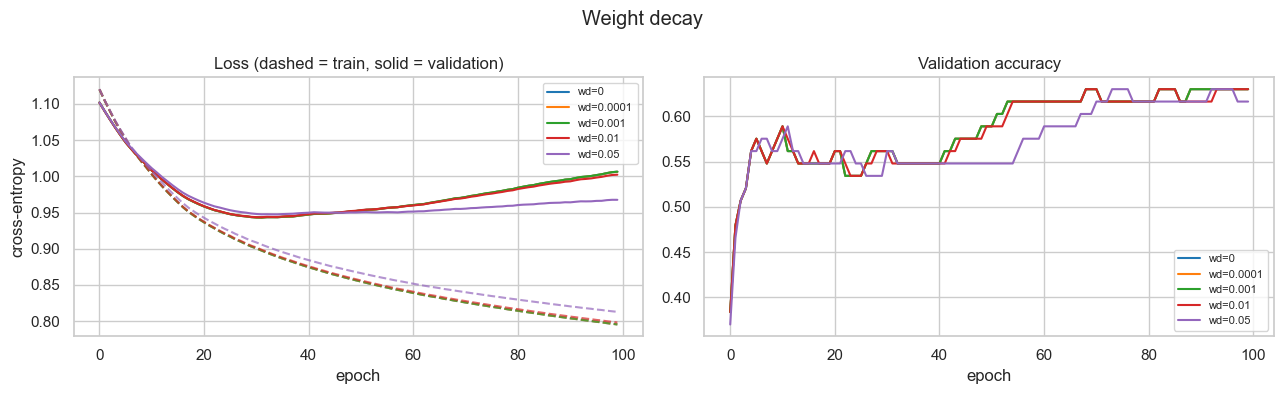

,config,parameters,best_epoch,epochs_run,train_loss,val_loss,train_acc,val_acc,final_train_loss,final_val_loss,final_train_acc,final_val_acc
0,dropout=0.75,1523,100,100,0.9213,0.9282,0.5426,0.6301,0.9213,0.9282,0.5426,0.6301
1,dropout=0.1,1523,38,100,0.8942,0.9411,0.5605,0.5479,0.8032,1.0031,0.6233,0.6301
2,dropout=0.25,1523,42,100,0.8930,0.9413,0.5650,0.5479,0.8243,0.9859,0.6009,0.6301
3,dropout=0,1523,32,100,0.8974,0.9430,0.5650,0.5616,0.7954,1.0064,0.6143,0.6301
4,dropout=0.5,1523,46,100,0.9224,0.9451,0.5336,0.5479,0.8487,0.9554,0.6099,0.6301


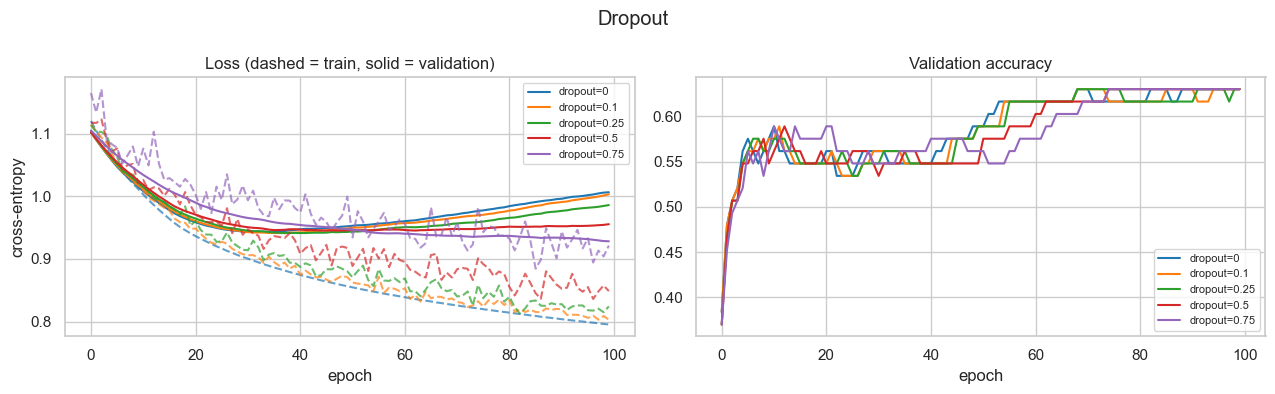

,method,best_epoch,train_loss,val_loss,train_acc,val_acc,final_val_loss
0,none,32,0.8974,0.9430,0.5650,0.5616,1.0064
1,best weight decay (0),32,0.8974,0.9430,0.5650,0.5616,1.0064
2,best dropout (0.75),100,0.9213,0.9282,0.5426,0.6301,0.9282


In [ ]:
base_cfg = {"hidden_dims": best_dims, "lr": best_lr}

wd_results = run_grid(
    {
        f"wd={wd:g}": {**base_cfg, "weight_decay": wd}
        for wd in [0.0, 1e-4, 1e-3, 1e-2, 5e-2]
    },
    epochs=100,
)
wd_table = results_table(wd_results)
display(wd_table.round(4))
plot_grid_curves(wd_results, "Weight decay", "weight_decay.png")

dropout_results = run_grid(
    {f"dropout={d:g}": {**base_cfg, "dropout": d} for d in [0.0, 0.1, 0.25, 0.5, 0.75]},
    epochs=100,
)
dropout_table = results_table(dropout_results)
display(dropout_table.round(4))
plot_grid_curves(dropout_results, "Dropout", "dropout.png")

best_wd = wd_results[wd_table.loc[0, "config"]]["config"].get("weight_decay", 0.0)
best_dropout = dropout_results[dropout_table.loc[0, "config"]]["config"].get(
    "dropout", 0.0
)

reg_summary = pd.DataFrame(
    [
        {"method": "none", **wd_results["wd=0"]["summary"]},
        {
            "method": f"best weight decay ({best_wd:g})",
            **wd_results[wd_table.loc[0, "config"]]["summary"],
        },
        {
            "method": f"best dropout ({best_dropout:g})",
            **dropout_results[dropout_table.loc[0, "config"]]["summary"],
        },
    ]
)[
    [
        "method",
        "best_epoch",
        "train_loss",
        "val_loss",
        "train_acc",
        "val_acc",
        "final_val_loss",
    ]
]
display(reg_summary.round(4))

,config,parameters,best_epoch,epochs_run,train_loss,val_loss,train_acc,val_acc
0,dropout,1523,109,124,0.8719,0.9263,0.5964,0.6301
1,weight decay + dropout,1523,109,124,0.8719,0.9263,0.5964,0.6301
2,no regularization,1523,32,47,0.8974,0.9430,0.5650,0.5616
3,weight decay,1523,32,47,0.8974,0.9430,0.5650,0.5616


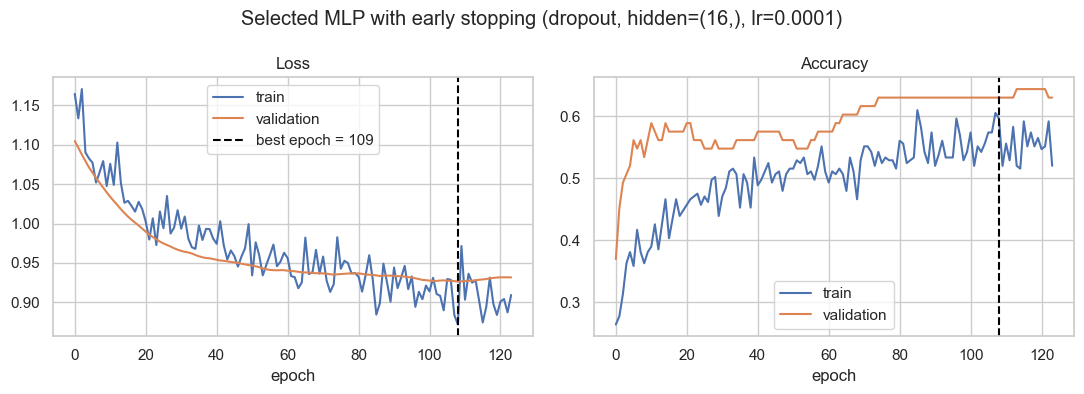

Selected configuration: dropout; hidden=(16,); lr=0.0001; best epoch=109 of 124 run; validation loss=0.9263; validation accuracy=0.630


In [ ]:
es_configs = {
    "no regularization": {**base_cfg},
    "weight decay": {**base_cfg, "weight_decay": best_wd},
    "dropout": {**base_cfg, "dropout": best_dropout},
    "weight decay + dropout": {
        **base_cfg,
        "weight_decay": best_wd,
        "dropout": best_dropout,
    },
}
es_results = run_grid(es_configs, epochs=300, patience=15)
es_table = results_table(es_results)
display(
    es_table[
        [
            "config",
            "parameters",
            "best_epoch",
            "epochs_run",
            "train_loss",
            "val_loss",
            "train_acc",
            "val_acc",
        ]
    ].round(4)
)

selected_name = es_table.loc[0, "config"]
selected = es_results[selected_name]
final_mlp = selected["model"]

plot_history(
    selected["history"],
    selected["best_epoch"],
    f"Selected MLP with early stopping ({selected_name}, hidden={best_dims}, lr={best_lr:g})",
    "learning_curves_selected.png",
)
print(
    f"Selected configuration: {selected_name}; hidden={best_dims}; lr={best_lr:g}; "
    f"best epoch={selected['best_epoch']} of {selected['summary']['epochs_run']} run; "
    f"validation loss={selected['summary']['val_loss']:.4f}; "
    f"validation accuracy={selected['summary']['val_acc']:.3f}"
)

In [ ]:
# XGBoost: small grid, selected on the validation partition only.
xgb_grid = ParameterGrid(
    {
        "n_estimators": [100, 300],
        "max_depth": [2, 4],
        "learning_rate": [0.05, 0.2],
        "colsample_bytree": [0.5, 1.0],
        "subsample": [0.8],
    }
)

xgb_rows = []
for params in xgb_grid:
    model_x = XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0,
        **params,
    )
    model_x.fit(X_train_imputed, y_train_np)
    pred_x = model_x.predict(X_val_imputed).astype(int)
    xgb_rows.append(
        {
            **params,
            "val_balanced_accuracy": balanced_accuracy_score(y_val_np, pred_x),
            "val_macro_f1": f1_score(y_val_np, pred_x, average="macro"),
        }
    )

xgb_table = (
    pd.DataFrame(xgb_rows)
    .sort_values(["val_macro_f1", "val_balanced_accuracy"], ascending=False)
    .reset_index(drop=True)
)
display(xgb_table.head(8).round(4))

best_xgb_params = {
    k: xgb_table.loc[0, k]
    for k in [
        "n_estimators",
        "max_depth",
        "learning_rate",
        "colsample_bytree",
        "subsample",
    ]
}
best_xgb_params["n_estimators"] = int(best_xgb_params["n_estimators"])
best_xgb_params["max_depth"] = int(best_xgb_params["max_depth"])

xgb_model = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=0,
    **best_xgb_params,
)
xgb_model.fit(X_train_imputed, y_train_np)
print("Selected XGBoost parameters:", best_xgb_params)

,colsample_bytree,learning_rate,max_depth,n_estimators,subsample,val_balanced_accuracy,val_macro_f1
0,1.0,0.05,2,100,0.8,0.5767,0.5799
1,0.5,0.05,4,100,0.8,0.5814,0.5765
2,0.5,0.05,4,300,0.8,0.5876,0.5725
3,1.0,0.20,4,300,0.8,0.5890,0.5696
4,0.5,0.05,2,100,0.8,0.5633,0.5659
5,1.0,0.05,4,100,0.8,0.5648,0.5634
6,1.0,0.05,4,300,0.8,0.5757,0.5586
7,1.0,0.20,4,100,0.8,0.5757,0.5586


Selected XGBoost parameters: {'n_estimators': 100, 'max_depth': 2, 'learning_rate': np.float64(0.05), 'colsample_bytree': np.float64(1.0), 'subsample': np.float64(0.8)}


,val_balanced_accuracy,val_macro_f1,test_balanced_accuracy,test_macro_f1,test_accuracy
model,,,,,
MLP,0.648,0.623,0.616,0.581,0.624
Logistic Regression,0.672,0.679,0.594,0.586,0.576
XGBoost,0.577,0.580,0.653,0.648,0.647


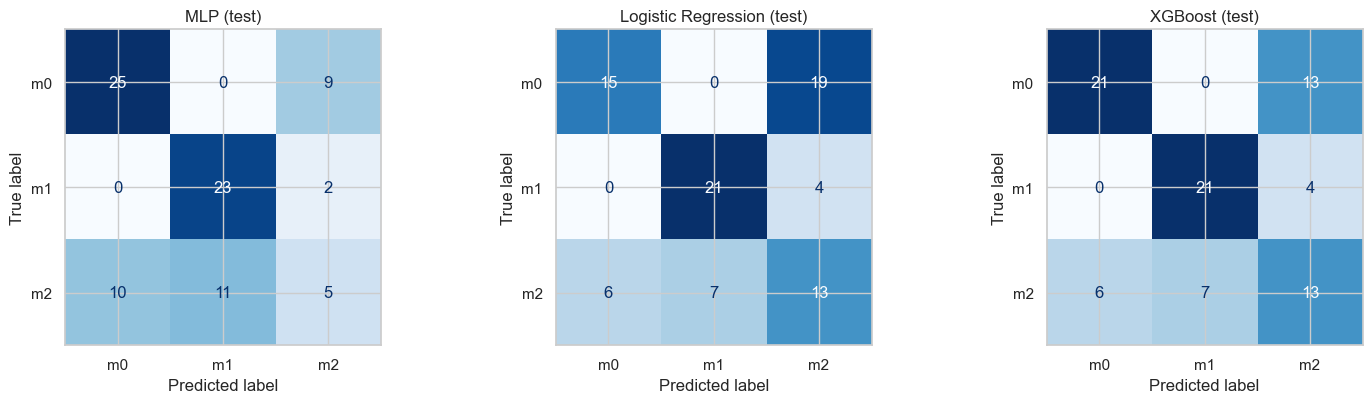

In [ ]:
@torch.no_grad()
def predict_mlp(model, X_t):
    model.eval()
    return model(X_t.to(DEVICE)).argmax(dim=1).cpu().numpy()


predictions = {
    "MLP": {
        "val": predict_mlp(final_mlp, X_val_t),
        "test": predict_mlp(final_mlp, X_test_t),
    },
    "Logistic Regression": {
        "val": logreg.predict(X_val_scaled),
        "test": logreg.predict(X_test_scaled),
    },
    "XGBoost": {
        "val": xgb_model.predict(X_val_imputed).astype(int),
        "test": xgb_model.predict(X_test_imputed).astype(int),
    },
}

rows = []
for name, p in predictions.items():
    rows.append(
        {
            "model": name,
            "val_balanced_accuracy": balanced_accuracy_score(y_val_np, p["val"]),
            "val_macro_f1": f1_score(y_val_np, p["val"], average="macro"),
            "test_balanced_accuracy": balanced_accuracy_score(y_test_np, p["test"]),
            "test_macro_f1": f1_score(y_test_np, p["test"], average="macro"),
            "test_accuracy": accuracy_score(y_test_np, p["test"]),
        }
    )

comparison = pd.DataFrame(rows).set_index("model")
display(comparison.round(3))
comparison.round(4).to_csv(FIG_DIR / "final_model_comparison.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, p) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_np,
        p["test"],
        labels=list(range(n_classes)),
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{name} (test)")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices_test.png", dpi=150)
plt.show()

### Final model comparison


In [ ]:
def error_analysis(name, y_true, y_pred):
    print("=" * 70)
    print(name)
    report = pd.DataFrame(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(n_classes)),
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0,
        )
    ).T
    display(report.round(3))

    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    confusions = [
        {
            "true": CLASS_NAMES[i],
            "predicted": CLASS_NAMES[j],
            "count": int(cm[i, j]),
            "share_of_true_class": round(cm[i, j] / cm[i].sum(), 3),
        }
        for i in range(n_classes)
        for j in range(n_classes)
        if i != j and cm[i, j] > 0
    ]
    confusions = pd.DataFrame(
        confusions, columns=["true", "predicted", "count", "share_of_true_class"]
    )
    display(confusions.sort_values("count", ascending=False).reset_index(drop=True))


for name, p in predictions.items():
    error_analysis(name, y_test_np, p["test"])

errors_by_group = (
    pd.DataFrame(
        {
            "sample_group": groups_test.to_numpy(),
            "true": y_test_np,
            "error": predictions["MLP"]["test"] != y_test_np,
        }
    )
    .groupby("sample_group")
    .agg(objects=("error", "size"), errors=("error", "sum"))
    .sort_values(["errors", "objects"], ascending=False)
)
print(
    "MLP: test groups with at least one error:",
    int((errors_by_group["errors"] > 0).sum()),
    "of",
    len(errors_by_group),
)
display(errors_by_group.head(10))

MLP


,precision,recall,f1-score,support
m0,0.714,0.735,0.725,34.000
m1,0.676,0.920,0.780,25.000
m2,0.312,0.192,0.238,26.000
accuracy,0.624,0.624,0.624,0.624
macro avg,0.568,0.616,0.581,85.000
weighted avg,0.580,0.624,0.592,85.000


,true,predicted,count,share_of_true_class
0,m2,m1,11,0.423
1,m2,m0,10,0.385
2,m0,m2,9,0.265
3,m1,m2,2,0.080


Logistic Regression


,precision,recall,f1-score,support
m0,0.714,0.441,0.545,34.000
m1,0.750,0.840,0.792,25.000
m2,0.361,0.500,0.419,26.000
accuracy,0.576,0.576,0.576,0.576
macro avg,0.608,0.594,0.586,85.000
weighted avg,0.617,0.576,0.580,85.000


,true,predicted,count,share_of_true_class
0,m0,m2,19,0.559
1,m2,m1,7,0.269
2,m2,m0,6,0.231
3,m1,m2,4,0.160


XGBoost


,precision,recall,f1-score,support
m0,0.778,0.618,0.689,34.000
m1,0.750,0.840,0.792,25.000
m2,0.433,0.500,0.464,26.000
accuracy,0.647,0.647,0.647,0.647
macro avg,0.654,0.653,0.648,85.000
weighted avg,0.664,0.647,0.651,85.000


,true,predicted,count,share_of_true_class
0,m0,m2,13,0.382
1,m2,m1,7,0.269
2,m2,m0,6,0.231
3,m1,m2,4,0.160


MLP: test groups with at least one error: 7 of 17


,objects,errors
sample_group,,
sample_group_081,13,10
sample_group_017,11,10
sample_group_079,13,5
sample_group_082,6,3
sample_group_005,4,2
sample_group_045,6,1
sample_group_075,2,1
sample_group_026,7,0
sample_group_033,3,0


## Report

**1. Did the embedding space show visible separation between the cell types?**

The silhouette score of the cell-type labels is 0.041 in the scaled embedding space and 0.066 in the t-SNE space, close to 0, so the classes overlap heavily and form no clear clusters. Some signal exists (classifiers reach ~0.6-0.65 accuracy versus ~0.33-0.38 for chance/majority), but the separation is partial. t-SNE is exploratory only. After removing 37 constant (all-zero) embedding dimensions, 91 features remained; there were no missing values, duplicates or label conflicts.

**2. Which learning rate and architecture performed best, and what evidence supports that choice?**

1e-4 had the lowest validation loss (1.006 vs 1.039 for 1e-3, 1.073 for 0.1 and 1.181 for 1e-2);
1e-2 was unstable (final validation loss 18.99) and 0.1 did not learn (accuracy 0.38-0.41, near the class prior).
the small network (16) had the lowest validation loss (0.943) versus medium 64-32 (0.971), deep 256-128-64 (0.976) and wide 256 (1.334).
The differences between small, medium and deep are small relative to the noise of a 73-object validation set, so the choice is the simplest model rather than proving it is better.

**3. Did the MLP overfit? Use the training and validation curves to justify your answer.**

Yes, and the overfitting grows with capacity. In the baseline MLP (32-16, lr=1e-3) training loss fell from 0.93 to 0.56 and training accuracy rose to 0.76, while validation loss was lowest early (~1.05 at epoch 5) and then rose to ~1.19, with validation accuracy stuck at ~0.62. For the wide and deep networks the best validation epoch was 8 and 12, and validation loss afterwards rose by 0.52 and 0.54 (final validation loss 1.85 and 1.51 versus training loss 0.66 and 0.60). The small network rose by only 0.06.

**4. Which regularization method was most useful?**

Dropout 0.75 gave the lowest validation loss (0.928 vs 0.943 without regularization) and the highest validation accuracy (0.630 vs 0.562), but its best epoch was the last one (100), i.e. it was still improving and trained slowly with train accuracy of only 0.54. Dropout 0.1/0.25/0.5 changed validation loss by less than 0.003. Weight decay had practically no effect (0.9430 at 0 to 0.9474 at 0.05). Early stopping (patience 15) stopped the unregularized model at epoch 47 (best 32) and let the dropout model run to epoch 124 (best 109, validation loss 0.926). Dropout combined with early stopping was most useful, but the gain (~0.017 loss) is small and within noise. Selected: hidden=(16,), lr=1e-4, dropout=0.75, weight decay=0 (the best weight decay was 0, so "weight decay + dropout" equals dropout), early stopping.

**5. How did the MLP compare with logistic regression and XGBoost?**

On the test set (85 objects) XGBoost was best (balanced accuracy 0.653, macro F1 0.648), the MLP had 0.616 / 0.581 and logistic regression 0.594 / 0.586. The ranking on validation was different (logistic regression 0.672 / 0.679 > MLP 0.648 / 0.623 > XGBoost 0.577 / 0.580), and models were selected on validation, not test. Since all models are at 0.58-0.65 and the test set is small and dominated by a few groups, none of them is clearly better; the MLP gave no advantage over the simpler models.

**7. Which cell types were most frequently confused?**

Class m2 is the hardest: MLP recall for m2 is 0.19 (21 of 26 m2 objects misclassified: 11 as m1, 10 as m0), with precision 0.31. The most frequent confusion overall is between m0 and m2: m0 to m2 was 9 times for the MLP, 19 for logistic regression (56% of m0) and 13 for XGBoost, and m2 was confused with m1 and m0 by all models. m1 was recognised best (recall 0.84-0.92, F1 ~0.78-0.79).

**8. What additional biological or technical information would help explain the errors?**

Errors are strongly concentrated in groups: 25 of the 32 MLP test errors come from three sample groups (sample_group_081: 10 of 13, sample_group_017: 10 of 11, sample_group_079: 5 of 13), which suggests a batch/experiment effect rather than random errors. Every sample group contains a single class, so group/batch effects are fully confounded with cell type. Useful additional information: experiment/batch metadata (date, microscope and acquisition settings, staining, sample preparation), per-object image quality and segmentation quality, object size and number of objects per group, and the raw images of misclassified groups. Biological annotation about whether m2 is a transitional/heterogeneous state between m0 and m1 would help interpret its confusion with both classes.

### Final model comparison

| Model                                           | Val balanced acc. | Val macro F1 | Test balanced acc. | Test macro F1 | Test accuracy |
| ----------------------------------------------- | ----------------: | -----------: | -----------------: | ------------: | ------------: |
| MLP (16, dropout 0.75, lr 1e-4, early stopping) |             0.648 |        0.623 |              0.616 |         0.581 |         0.624 |
| Logistic Regression (C=1)                       |             0.672 |        0.679 |              0.594 |         0.586 |         0.576 |
| XGBoost (100 trees, depth 2, lr 0.05)           |             0.577 |        0.580 |              0.653 |         0.648 |         0.647 |

### Limitations and next steps

- Small dataset (381 objects, 85 sample groups): a single group-aware train/validation/test split gives high-variance estimates; test scores rest on few groups and few objects per class.
- Hyperparameters were chosen on one validation partition only; repeated or nested group-aware cross-validation would give more reliable model ranking and confidence intervals.
- Embedding dimensionality is large relative to the number of objects, which favours overfitting; dimensionality reduction (PCA) or stronger regularization could be tested.
- Sample groups may correspond to batches or experiments; batch effects can be confounded with cell type, so group-level performance should be inspected.
- t-SNE is exploratory only; distances and cluster shapes in the embedding do not constitute evidence of class separability.
- Next steps: repeated group-aware CV, comparison with the handcrafted-feature representation, calibration of predicted probabilities, and combining embeddings with handcrafted features.


ai usage report: i asked copilot to help with structuring the text report